# OH–H₂O coadsorption: manuscript analysis

Run all cells from top to bottom with the three curated ASE databases in `DATA_DIR`.
The coadsorption database contains the interaction-energy components, Bader charges, and magnetic moments.
Figure outputs are written to `analysis_outputs/`.
Figure 1 (representative structures) and Figure SI1 (workflow) are prepared separately.


## 1. Setup

### 1.1 Imports, database paths, and analysis constants


In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from ase.db import connect
from ase.data import covalent_radii, atomic_numbers
from sklearn.mixture import GaussianMixture

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", "{:.4f}".format)

RANDOM_STATE = 0
N_BOOTSTRAP = 4000

DATA_DIR = Path(".")
DB_COADS = DATA_DIR / "DASC_OH_H2O_Coadsorption_RPBE_D4.db"
DB_SINGLE_H2O = DATA_DIR / "DASC_H2O_Adsorption_RPBE_D4.db"
DB_BARE = DATA_DIR / "DASC_Bare_Catalysts_RPBE_D4.db"

OUTPUT_DIR = Path("analysis_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FIG_WIDTH_CM = 8.25
FIG_WIDTH_IN = FIG_WIDTH_CM / 2.54


H2O_ENV_ORDER = [
    "1 H2O far from both OH and metal",
    "2 H2O close to metal only",
    "3 H2O close to OH only",
    "4 H2O close to both OH and metal",
]

ENV_H2O = {
    "1": r"$\mathrm{OH}_2{\cdot}{\cdot}{\cdot}{\ast}\mathrm{OH}$",
    "2": r"${\ast}\mathrm{OH}_2{\cdot}{\cdot}{\cdot}{\ast}\mathrm{OH}$",
    "3": r"$\mathrm{OH}_2{-}{\ast}\mathrm{OH}$",
    "4": r"${\ast}\mathrm{OH}_2{-}{\ast}\mathrm{OH}$",
}

ENV_COLOR = {
    "1": "#1f77b4",
    "2": "#d62728",
    "3": "#ff7f0e",
    "4": "#2ca02c",
}

LEGEND_TITLE = r"GMM H$_2$O environment"

def _env_key(group):
    return str(group).split()[0]

def env_label(group):
    return ENV_H2O[_env_key(group)]

def env_color(group):
    return ENV_COLOR[_env_key(group)]

def plain_label(text):
    return (
        str(text)
        .replace("$", "")
        .replace("^", "")
        .replace("{", "")
        .replace("}", "")
        .replace(r"\mathrm", "")
    )




### 1.2 Figure style


In [2]:
MPL_DPI = 300
MPL_MARKER_SIZE = 7
MPL_EDGE_WIDTH = 0.25
MPL_LINE_WIDTH = 1.0
MPL_LEGEND_SIZE = 8
MPL_LABEL_SIZE = 9
MPL_FONT_SIZE = 8
MPL_TICK_SIZE = 9

mpl.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "dejavuserif",
    "figure.figsize": (FIG_WIDTH_IN, FIG_WIDTH_IN),
    "figure.dpi": MPL_DPI,
    "font.size": MPL_FONT_SIZE,
    "axes.labelsize": MPL_LABEL_SIZE,
    "legend.fontsize": MPL_LEGEND_SIZE,
    "xtick.labelsize": MPL_TICK_SIZE,
    "ytick.labelsize": MPL_TICK_SIZE,
    "lines.markersize": MPL_MARKER_SIZE,
    "lines.markeredgewidth": MPL_EDGE_WIDTH,
    "lines.linewidth": MPL_LINE_WIDTH,
})


### 1.3 Validate input databases


In [3]:
from IPython.display import display

for db_path in (DB_COADS, DB_SINGLE_H2O, DB_BARE):
    if not db_path.is_file():
        raise FileNotFoundError(db_path)


## 2. Geometry, energies, and classification

### 2.1 Atom indices and geometric descriptors


In [4]:
def block_geom(n_cat, n1, n2, ads1, ads2, acid):
    """Resolve indices for OH, H2O, and their hosting metals."""
    # A1 transmutation appends six methyl H atoms after the original block.
    cutoff = 6 if acid == "A1" else 0

    block1 = (n_cat - cutoff, n_cat + n1 - cutoff)
    block2 = (n_cat + n1 - cutoff, n_cat + n1 + n2 - cutoff)

    if ads1 == "OH":
        (oh_start, _), oh_metal = block1, 0
        (h2o_start, _), h2o_metal = block2, 1
    else:
        (oh_start, _), oh_metal = block2, 1
        (h2o_start, _), h2o_metal = block1, 0

    return {
        "O_OH": oh_start,
        "H_OH": oh_start + 1,
        "O_H2O": h2o_start,
        "H2O_Hs": [h2o_start + 1, h2o_start + 2],
        "metal_OH": oh_metal,
        "metal_H2O": h2o_metal,
    }


def compute_descriptors(atoms, geometry):
    """Only descriptors needed for the figures and original transfer exclusion."""
    atoms = atoms.copy()
    atoms.pbc = False
    distance = lambda i, j: atoms.get_distance(i, j, mic=False)
    O_OH = geometry["O_OH"]
    O_H2O = geometry["O_H2O"]
    water_H = geometry["H2O_Hs"]
    metal_H2O = geometry["metal_H2O"]
    H_bridge = water_H[int(np.argmin([distance(O_OH, h) for h in water_H]))]
    d_O_OH_H = distance(O_OH, H_bridge)
    d_O_H2O_H = distance(O_H2O, H_bridge)
    h1, h2 = water_H
    d1 = distance(O_H2O, h1)
    d2 = distance(O_H2O, h2)
    d_hh = distance(h1, h2)
    cos_theta = np.clip(
        (d1**2 + d2**2 - d_hh**2) / (2 * d1 * d2),
        -1.0,
        1.0,
    )
    H2O_angle = np.degrees(np.arccos(cos_theta))

    return {
        "H2O_angle": H2O_angle,
        "d_O_O": distance(O_OH, O_H2O),
        "d_O_H2O_M": (
            distance(O_H2O, metal_H2O)
            - covalent_radii[atomic_numbers["O"]]
            - covalent_radii[atomic_numbers[atoms[metal_H2O].symbol]]
        ),
        "d_O_H2O_H": d_O_H2O_H,
        # Exactly the original delta_H <= 0 test; used only for exclusion.
        "h_transfer": bool((d_O_OH_H - d_O_H2O_H) <= 0.0),
    }


### 2.2 Interaction energies and intact coadsorption structures


In [5]:
ENERGY_KEYS = [
    "coads_rpbe_d4_E",
    "sp_rpbe_d4_E_bare_cat",
    "sp_rpbe_d4_E_only_ads1",
    "sp_rpbe_d4_E_only_ads2",
]


def parse_sp_db(db_path):
    records = []

    with connect(db_path) as database:
        for row in database.select():
            if row.get("state") not in (None, "OH_H2O"):
                continue

            ads1 = row.get("ads1")
            ads2 = row.get("ads2")
            if {ads1, ads2} != {"OH", "H2O"}:
                continue

            energies = {key: row.get(key) for key in ENERGY_KEYS}
            if any(value is None for value in energies.values()):
                continue

            n_cat = row.get("n_cat_atoms")
            n1 = row.get("n_ads1")
            n2 = row.get("n_ads2")
            metal1 = row.get("metal1")
            metal2 = row.get("metal2")
            acid = row.get("acid")

            if None in (n_cat, n1, n2, metal1, metal2):
                continue

            geometry = block_geom(
                int(n_cat),
                int(n1),
                int(n2),
                ads1,
                ads2,
                acid,
            )
            descriptors = compute_descriptors(row.toatoms(), geometry)

            E_interaction = (
                energies["coads_rpbe_d4_E"]
                + energies["sp_rpbe_d4_E_bare_cat"]
                - energies["sp_rpbe_d4_E_only_ads1"]
                - energies["sp_rpbe_d4_E_only_ads2"]
            )

            oh_metal = metal1 if ads1 == "OH" else metal2
            h2o_metal = metal1 if ads1 == "H2O" else metal2

            records.append({
                "name": row.get("name"),
                "metal1": metal1,
                "metal2": metal2,
                "oh_metal": oh_metal,
                "h2o_metal": h2o_metal,
                "base": row.get("base"),
                "acid": acid,
                "bridge": row.get("bridge"),
                "total_charge": row.get("total_charge"),
                "ads1": ads1,
                "ads2": ads2,
                "E_interaction": E_interaction,
                **descriptors,
            })

    return pd.DataFrame(records)


df_all = parse_sp_db(str(DB_COADS))
if df_all.empty:
    raise ValueError("No complete OH + H2O records found.")
df = df_all.loc[~df_all["h_transfer"]].copy()
print(f"Loaded: {len(df_all)}; proton-transferred, dropped: {len(df_all) - len(df)}; retained: {len(df)}")
if df.empty:
    raise ValueError("No intact structures remain.")


Loaded: 1659; proton-transferred, dropped: 0; retained: 1659


### 2.3 Substitution-family identifiers


In [6]:
FAMILY_RE = re.compile(r"_A(?:1|2|4|5|6|9)_")


def family_key(name):
    """Collapse only the acid token; preserve the ordered adsorbate orientation."""
    key, n_replaced = FAMILY_RE.subn("_A*_", str(name), count=1)
    if n_replaced != 1:
        warnings.warn(f"Could not identify exactly one acid token in {name!r}.")
    return key


df["family"] = df["name"].map(family_key)
print(f"Orientation-preserving families: {df['family'].nunique()}")


Orientation-preserving families: 294


### 2.4 Gaussian-mixture classification


In [7]:
def fit_1d_gmm_threshold(
    data,
    col,
    *,
    random_state=RANDOM_STATE,
    n_grid=4000,
):
    """Fit a 2-component 1D GMM and find the equal-posterior boundary."""
    x = (
        data[col]
        .dropna()
        .astype(float)
        .to_numpy()
        .reshape(-1, 1)
    )

    if len(x) < 2:
        raise ValueError(
            f"Not enough finite values in {col!r} for a 2-component GMM."
        )

    gmm = GaussianMixture(
        n_components=2,
        covariance_type="full",
        n_init=20,
        random_state=random_state,
    ).fit(x)

    means = gmm.means_.ravel()
    order = np.argsort(means)
    close_component, far_component = order[0], order[1]

    grid = np.linspace(
        float(x.min()),
        float(x.max()),
        n_grid,
    ).reshape(-1, 1)

    probabilities = gmm.predict_proba(grid)
    grid_1d = grid.ravel()

    between_means = (
        (grid_1d >= means[close_component])
        & (grid_1d <= means[far_component])
    )
    difference = np.abs(
        probabilities[:, close_component]
        - probabilities[:, far_component]
    )

    candidate_indices = np.where(between_means)[0]
    if len(candidate_indices):
        index = candidate_indices[
            np.argmin(difference[candidate_indices])
        ]
    else:
        index = int(
            np.argmin(np.abs(grid_1d - np.mean(means)))
        )

    info = {
        "descriptor": col,
        "threshold": float(grid_1d[index]),
        "close_mean": float(means[close_component]),
        "far_mean": float(means[far_component]),
        "close_weight": float(gmm.weights_[close_component]),
        "far_weight": float(gmm.weights_[far_component]),
    }

    return gmm, info


def add_h2o_environment_groups(
    data,
    d_OO_col="d_O_O",
    d_H2O_M_col="d_O_H2O_M",
):
    output = data.copy()

    gmm_OO, info_OO = fit_1d_gmm_threshold(output, d_OO_col)
    gmm_OM, info_OM = fit_1d_gmm_threshold(output, d_H2O_M_col)

    threshold_OO = info_OO["threshold"]
    threshold_OM = info_OM["threshold"]

    valid = output[[d_OO_col, d_H2O_M_col]].notna().all(axis=1)

    output["dOO_region"] = pd.NA
    output["d_H2O_M_region"] = pd.NA

    output.loc[valid, "dOO_region"] = np.where(
        output.loc[valid, d_OO_col] <= threshold_OO,
        "close to OH",
        "far from OH",
    )
    output.loc[valid, "d_H2O_M_region"] = np.where(
        output.loc[valid, d_H2O_M_col] <= threshold_OM,
        "close to metal",
        "far from metal",
    )

    close_OH = output["dOO_region"].eq("close to OH")
    far_OH = output["dOO_region"].eq("far from OH")
    close_metal = output["d_H2O_M_region"].eq("close to metal")
    far_metal = output["d_H2O_M_region"].eq("far from metal")

    output["h2o_env"] = pd.NA
    output.loc[
        valid & far_OH & far_metal,
        "h2o_env",
    ] = H2O_ENV_ORDER[0]
    output.loc[
        valid & far_OH & close_metal,
        "h2o_env",
    ] = H2O_ENV_ORDER[1]
    output.loc[
        valid & close_OH & far_metal,
        "h2o_env",
    ] = H2O_ENV_ORDER[2]
    output.loc[
        valid & close_OH & close_metal,
        "h2o_env",
    ] = H2O_ENV_ORDER[3]

    output["h2o_env"] = pd.Categorical(
        output["h2o_env"],
        categories=H2O_ENV_ORDER,
        ordered=True,
    )

    thresholds = {
        d_OO_col: threshold_OO,
        d_H2O_M_col: threshold_OM,
    }
    models = {
        d_OO_col: gmm_OO,
        d_H2O_M_col: gmm_OM,
    }
    information = pd.DataFrame([info_OO, info_OM])

    return output, thresholds, models, information


df, GMM_THRESHOLDS, GMM_MODELS, GMM_INFO = (
    add_h2o_environment_groups(df)
)

display(GMM_INFO.round(4))

class_counts = (
    df["h2o_env"]
    .value_counts(sort=False, dropna=False)
    .rename_axis("h2o_env")
    .to_frame("rows")
)
class_counts["label"] = [
    plain_label(env_label(group))
    if pd.notna(group)
    else "unclassified"
    for group in class_counts.index
]
display(class_counts)


,descriptor,threshold,close_mean,far_mean,close_weight,far_weight
0,d_O_O,3.0689,2.7081,3.5035,0.8679,0.1321
1,d_O_H2O_M,0.5613,0.3176,0.7595,0.7191,0.2809


,rows,label
h2o_env,,
1 H2O far from both OH and metal,102,OH_2\cdot\cdot\cdot\astOH
2 H2O close to metal only,112,\astOH_2\cdot\cdot\cdot\astOH
3 H2O close to OH only,341,OH_2-\astOH
4 H2O close to both OH and metal,1104,\astOH_2-\astOH


### 2.5 Sulfur content of Resonance-Off structures


In [8]:
off = df.loc[df["h2o_env"].isin(H2O_ENV_ORDER[:3])]
print("Resonance-Off total:", len(off))
print(off["bridge"].value_counts(dropna=False))

n_s = off["bridge"].astype("string").str.contains("S", na=False).sum()
print(f"Sulfur-containing: {n_s}/{len(off)} = {100*n_s/len(off):.1f}%")


Resonance-Off total: 555
bridge
SS    219
NS    125
OS     82
NO     51
NN     40
OO     38
Name: count, dtype: int64
Sulfur-containing: 426/555 = 76.8%


## 3. Energy statistics

### 3.1 Nonadditive energy decomposition


In [9]:
def energy_factorial_decomposition(class_means):
    mu00, mu01, mu10, mu11 = [float(class_means.loc[group]) for group in H2O_ENV_ORDER]
    metal_effect = mu01 - mu00
    hbond_effect = mu10 - mu00
    additive_prediction = mu00 + metal_effect + hbond_effect
    additional_effect = mu11 - additive_prediction
    return {
        "baseline": mu00,
        "metal_coordination": metal_effect,
        "hbond": hbond_effect,
        "additive_prediction": additive_prediction,
        "observed_both": mu11,
        "additional_effect": additional_effect,
    }


### 3.2 Family-level means and cluster bootstrap


In [10]:
family_group_energy = (
    df.groupby(["family", "h2o_env"], observed=True)
    .agg(E_interaction=("E_interaction", "mean"))
    .reset_index()
)
family_group_energy["h2o_env"] = pd.Categorical(
    family_group_energy["h2o_env"], categories=H2O_ENV_ORDER, ordered=True
)
class_mean_energy = (
    family_group_energy.groupby("h2o_env", observed=True)["E_interaction"]
    .mean().reindex(H2O_ENV_ORDER)
)
point_est = energy_factorial_decomposition(class_mean_energy)

family_group_pivot = (
    family_group_energy.pivot(index="family", columns="h2o_env", values="E_interaction")
    .reindex(columns=H2O_ENV_ORDER)
)
boot_matrix = family_group_pivot.to_numpy(float)
rng_c = np.random.default_rng(RANDOM_STATE)
boot_group_means, boot_coop = [], []
for _ in range(N_BOOTSTRAP):
    idx = rng_c.integers(0, len(boot_matrix), size=len(boot_matrix))
    sampled = boot_matrix[idx, :]
    if not np.isfinite(sampled).any(axis=0).all():
        continue
    means = np.nanmean(sampled, axis=0)
    boot_group_means.append(means)
    boot_coop.append(energy_factorial_decomposition(pd.Series(means, index=H2O_ENV_ORDER))["additional_effect"])
boot_group_means = np.asarray(boot_group_means)
boot_coop = np.asarray(boot_coop)
group_ci = np.percentile(boot_group_means, [2.5, 97.5], axis=0)
coop_ci = np.percentile(boot_coop, [2.5, 97.5])


### 3.3 Family-level energy summary


In [11]:
print("Family-weighted structural-group means")
display(class_mean_energy.round(4).to_frame("mean_E_interaction"))
print("Family-cluster bootstrap: E_res")
display(pd.DataFrame([{
    "additive_prediction_eV": point_est["additive_prediction"],
    "observed_on_eV": point_est["observed_both"],
    "E_res_eV": point_est["additional_effect"],
    "CI95_low_eV": coop_ci[0],
    "CI95_high_eV": coop_ci[1],
    "bootstrap_replicates": len(boot_coop),
}]).round(4))


Family-weighted structural-group means


,mean_E_interaction
h2o_env,
1 H2O far from both OH and metal,-0.0630
2 H2O close to metal only,-0.1032
3 H2O close to OH only,-0.2457
4 H2O close to both OH and metal,-0.4901


Family-cluster bootstrap: E_res


,additive_prediction_eV,observed_on_eV,E_res_eV,CI95_low_eV,CI95_high_eV,bootstrap_replicates
0,-0.2859,-0.4901,-0.2042,-0.2473,-0.1607,4000


### 3.4 Composition clusters for Resonance-On comparisons


In [12]:
composition_data = df.copy().reset_index(drop=True)
composition_data["family"] = (
    composition_data["metal1"] + "|" + composition_data["metal2"] + "|"
    + composition_data["bridge"] + "|" + composition_data["base"] + "|"
    + composition_data["total_charge"].astype(str)
)
df_dp = composition_data.loc[
    composition_data["h2o_env"].astype(str).eq(H2O_ENV_ORDER[3])
].copy()
if df_dp.empty:
    raise ValueError("No Resonance On structures available.")
families_dp = df_dp["family"].to_numpy()
uniq_fams_dp = pd.unique(families_dp)
fam_to_idx_dp = {f: np.where(families_dp == f)[0] for f in uniq_fams_dp}
print(f"Resonance On structures: {len(df_dp)}; comparison-family clusters: {len(uniq_fams_dp)}")


Resonance On structures: 1104; comparison-family clusters: 156


### 3.5 Metal and bridge means with bootstrap intervals


In [13]:
def raw_mean_bootstrap(data, level_col, fam_to_idx, uniq_fams, n_boot=N_BOOTSTRAP, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    levels = sorted(data[level_col].unique())
    point = {lvl: data.loc[data[level_col] == lvl, "E_interaction"].mean() for lvl in levels}
    n_by = {lvl: int((data[level_col] == lvl).sum()) for lvl in levels}

    boots = {lvl: np.empty(n_boot) for lvl in levels}
    for b in range(n_boot):
        sampled_fams = rng.choice(uniq_fams, size=len(uniq_fams), replace=True)
        idx = np.concatenate([fam_to_idx[f] for f in sampled_fams])
        sample = data.iloc[idx]
        for lvl in levels:
            sub = sample.loc[sample[level_col] == lvl, "E_interaction"]
            boots[lvl][b] = sub.mean() if len(sub) else np.nan

    rows = []
    for lvl in levels:
        v = boots[lvl][~np.isnan(boots[lvl])]
        lo, hi = np.percentile(v, [2.5, 97.5])
        rows.append({"level": lvl, "n": n_by[lvl], "mean_eV": point[lvl], "ci_lo": lo, "ci_hi": hi})
    return pd.DataFrame(rows).sort_values("mean_eV").reset_index(drop=True)


by_metal_dp = raw_mean_bootstrap(df_dp, "h2o_metal", fam_to_idx_dp, uniq_fams_dp, seed=RANDOM_STATE)
by_bridge_dp = raw_mean_bootstrap(df_dp, "bridge", fam_to_idx_dp, uniq_fams_dp, seed=RANDOM_STATE + 1)

print("Dual-proximal, absolute mean E_interaction by H2O-hosting metal:")
display(by_metal_dp.round(3))
print("\nDual-proximal, absolute mean E_interaction by bridge:")
display(by_bridge_dp.round(3))


Dual-proximal, absolute mean E_interaction by H2O-hosting metal:


,level,n,mean_eV,ci_lo,ci_hi
0,Ni,25,-0.8090,-0.9350,-0.6420
1,Cr,154,-0.5340,-0.6290,-0.4470
2,Mn,254,-0.5180,-0.5680,-0.4700
3,Co,289,-0.5070,-0.5460,-0.4690
4,Fe,254,-0.4840,-0.5220,-0.4470
5,Cu,128,-0.2820,-0.3120,-0.2520



Dual-proximal, absolute mean E_interaction by bridge:


,level,n,mean_eV,ci_lo,ci_hi
0,NO,221,-0.5440,-0.6110,-0.4790
1,OS,238,-0.4930,-0.5450,-0.4440
2,OO,202,-0.4890,-0.5680,-0.4050
3,NS,180,-0.4810,-0.5460,-0.4240
4,NN,177,-0.4640,-0.5170,-0.4150
5,SS,86,-0.3980,-0.4510,-0.3530


### 3.6 Para-substituent means with bootstrap intervals


In [14]:
# Para-substitution: Resonance On only.
substituent_labels = {
    "A2": "H",
    "A1": r"CH$_3$",
    "A9": "F",
    "A4": "Cl",
    "A5": "Br",
    "A6": "I",
}
substituent_order = list(substituent_labels.values())

sub_on = df.loc[
    df["h2o_env"].astype(str).eq(H2O_ENV_ORDER[3])
    & df["acid"].isin(substituent_labels)
].copy()

if sub_on.empty:
    raise ValueError("No Resonance On structures for these substituents.")

sub_on["substituent"] = sub_on["acid"].map(substituent_labels)

# Same cluster definition as the metal/bridge comparison.
sub_on["family"] = (
    sub_on["metal1"] + "|" + sub_on["metal2"] + "|"
    + sub_on["bridge"] + "|" + sub_on["base"] + "|"
    + sub_on["total_charge"].astype(str)
)

families = sub_on["family"].to_numpy()
unique_families = pd.unique(families)
family_indices = {
    family: np.flatnonzero(families == family)
    for family in unique_families
}

by_substituent_dp = raw_mean_bootstrap(
    sub_on,
    "substituent",
    family_indices,
    unique_families,
    seed=RANDOM_STATE + 2,
)


## 4. Bare and single-water references

### 4.1 Bare-catalyst metal–metal distances


In [15]:
if not DB_BARE.is_file():
    raise FileNotFoundError(DB_BARE)

# Derive bare-catalyst names; retain the original coadsorbed groups.
plot_data = df[["name", "h2o_env"]].copy()
plot_data["bare_name"] = plot_data["name"].str.extract(
    r"^(.*)_(?:OH_metal1_H2O_metal2|H2O_metal1_OH_metal2)$",
    expand=False,
)
if plot_data["bare_name"].isna().any():
    raise ValueError("Some coadsorbed names have an unrecognized suffix.")

# Calculate M–M distances from optimized bare structures only.
wanted = set(plot_data["bare_name"])
bare_distances = {}

with connect(str(DB_BARE)) as database:
    for row in database.select():
        name = row.get("name")
        if name not in wanted:
            continue
        if name in bare_distances:
            raise ValueError(f"Duplicate bare-catalyst name: {name}")

        atoms = row.toatoms()
        metal_indices = np.flatnonzero(
            (atoms.numbers >= 21) & (atoms.numbers <= 30)
        )
        if len(metal_indices) != 2:
            raise ValueError(f"{name}: expected exactly two 3d metals.")

        i, j = map(int, metal_indices)
        bare_distances[name] = atoms.get_distance(i, j, mic=False)

plot_data["d_M_M_bare"] = plot_data["bare_name"].map(bare_distances)

missing = plot_data["d_M_M_bare"].isna()
print(f"Matched: {(~missing).sum()} / {len(plot_data)} coadsorbed structures")
if missing.any():
    print("Unmatched structures:")
    display(plot_data.loc[missing, ["name", "bare_name"]])

plot_data = plot_data.dropna(subset=["d_M_M_bare", "h2o_env"])
if plot_data.empty:
    raise ValueError("No matched structures available to plot.")

# Optional: count each bare catalyst once per coadsorption group.
# plot_data = plot_data.drop_duplicates(["bare_name", "h2o_env"])

bare_mm_edges = np.histogram_bin_edges(plot_data["d_M_M_bare"], bins=24)
bare_mm_env = plot_data["h2o_env"].astype(str)


Matched: 1653 / 1659 coadsorbed structures
Unmatched structures:


,name,bare_name
1210,KMC_Mn_Cu_A1_B1_NNNNOO_q2_OH_metal1_H2O_metal2,KMC_Mn_Cu_A1_B1_NNNNOO_q2
1213,KMC_Mn_Cu_A1_B2_NNNNNS_q2_OH_metal1_H2O_metal2,KMC_Mn_Cu_A1_B2_NNNNNS_q2
1215,KMC_Mn_Cu_A2_B1_NNNNOO_q2_OH_metal1_H2O_metal2,KMC_Mn_Cu_A2_B1_NNNNOO_q2
1223,KMC_Mn_Cu_A4_B2_NNNNNS_q2_OH_metal1_H2O_metal2,KMC_Mn_Cu_A4_B2_NNNNNS_q2
1227,KMC_Mn_Cu_A5_B1_NNNNOO_q2_OH_metal1_H2O_metal2,KMC_Mn_Cu_A5_B1_NNNNOO_q2
1239,KMC_Mn_Cu_A9_B1_NNNNOO_q2_OH_metal1_H2O_metal2,KMC_Mn_Cu_A9_B1_NNNNOO_q2


### 4.2 Single-water reference distances


In [16]:
if not DB_SINGLE_H2O.is_file():
    raise FileNotFoundError(DB_SINGLE_H2O)

single_records = []

with connect(str(DB_SINGLE_H2O)) as database:
    for row in database.select():
        name = row.get("name", "")

        # Identify the water-binding metal from the structure name.
        match = re.search(r"(?:^|_)H2O_metal([12])(?:_|$)", name)
        if match is None:
            raise ValueError(f"Cannot identify the H2O-hosting metal: {name!r}")

        metal_index = int(match.group(1)) - 1
        atoms = row.toatoms()
        oxygen_index = len(atoms) - 3

        # Validate the assumed final O, H, H block.
        if atoms.get_chemical_symbols()[-3:] != ["O", "H", "H"]:
            raise ValueError(f"{name}: the final three atoms are not O, H, H.")

        metal_symbol = atoms[metal_index].symbol
        delta_d = (
            atoms.get_distance(oxygen_index, metal_index, mic=False)
            - covalent_radii[atomic_numbers["O"]]
            - covalent_radii[atomic_numbers[metal_symbol]]
        )

        single_records.append({
            "name": name,
            "h2o_metal": metal_symbol,
            "d_O_H2O_M": delta_d,
        })

single_h2o = pd.DataFrame(single_records)
if single_h2o.empty:
    raise ValueError("No single-H2O structures found.")

resonance_on = df.loc[
    df["h2o_env"].astype(str).eq(H2O_ENV_ORDER[3]),
    "d_O_H2O_M",
].dropna().to_numpy(float)

single_distances = single_h2o["d_O_H2O_M"].dropna().to_numpy(float)

resonance_on = resonance_on[np.isfinite(resonance_on)]
single_distances = single_distances[np.isfinite(single_distances)]
if not len(resonance_on) or not len(single_distances):
    raise ValueError("Both datasets need finite distances.")

# Shared bin edges.
edges = np.histogram_bin_edges(
    np.concatenate([resonance_on, single_distances]),
    bins=24,
)


### 4.3 Match water-hosting sites and calculate distance differences


In [17]:
# Match catalyst composition AND H2O-hosting site.
# Example:
# ..._H2O_metal1 <-> ..._H2O_metal1_OH_metal2

coads = df.loc[
    df["h2o_env"].astype(str).eq(H2O_ENV_ORDER[3]),
    ["name", "d_O_H2O_M"],
].copy()

single = single_h2o[["name", "d_O_H2O_M"]].copy()

coads_parts = coads["name"].str.extract(
    r"^(?P<catalyst>.+)_(?:"
    r"H2O_metal(?P<water_first>[12])_OH_metal[12]"
    r"|OH_metal[12]_H2O_metal(?P<water_last>[12]))$"
)
coads["catalyst"] = coads_parts["catalyst"]
coads["water_site"] = coads_parts["water_first"].fillna(
    coads_parts["water_last"]
)

single_parts = single["name"].str.extract(
    r"^(?P<catalyst>.+)_H2O_metal(?P<water_site>[12])$"
)
single[["catalyst", "water_site"]] = single_parts

keys = ["catalyst", "water_site"]

for label, table in [("Coadsorption", coads), ("Single H2O", single)]:
    invalid = table[keys].isna().any(axis=1)
    if invalid.any():
        raise ValueError(
            f"{label}: cannot parse these names:\n"
            + "\n".join(table.loc[invalid, "name"])
        )

# Avoid silently choosing among duplicate single-adsorption references.
duplicates = single.duplicated(keys, keep=False)
if duplicates.any():
    display(single.loc[duplicates].sort_values(keys))
    raise ValueError("Multiple single-H2O references for the same catalyst/site.")

matched = coads.merge(
    single,
    on=keys,
    how="left",
    suffixes=("_coads", "_single"),
    validate="many_to_one",
    indicator=True,
)

missing = matched["_merge"].eq("left_only")
print(f"Matched references: {(~missing).sum()} / {len(matched)}")
if missing.any():
    display(matched.loc[missing, ["name_coads", "water_site"]])

matched = matched.loc[
    ~missing
    & np.isfinite(matched["d_O_H2O_M_coads"])
    & np.isfinite(matched["d_O_H2O_M_single"])
].copy()

matched["distance_difference"] = (
    matched["d_O_H2O_M_coads"] - matched["d_O_H2O_M_single"]
)

if matched.empty:
    raise ValueError("No valid matched Resonance On / single-H2O pairs.")

differences = matched["distance_difference"].to_numpy()


Matched references: 152 / 1104


,name_coads,water_site
0,KMC_Co_Co_A1_B1_NNNNNN_q2_OH_metal1_H2O_metal2,2
1,KMC_Co_Co_A1_B1_NNNNNO_q2_OH_metal1_H2O_metal2,2
2,KMC_Co_Co_A1_B1_NNNNNS_q2_OH_metal1_H2O_metal2,2
3,KMC_Co_Co_A1_B1_NNNNOO_q2_OH_metal1_H2O_metal2,2
4,KMC_Co_Co_A1_B1_NNNNOS_q2_OH_metal1_H2O_metal2,2
...,...,...
1099,KMC_Ni_Ni_A4_B2_NNNNNO_q2_OH_metal1_H2O_metal2,2
1100,KMC_Ni_Ni_A5_B1_NNNNNN_q2_OH_metal1_H2O_metal2,2
1101,KMC_Ni_Ni_A5_B2_NNNNNO_q2_OH_metal1_H2O_metal2,2
1102,KMC_Ni_Ni_A6_B1_NNNNNN_q2_OH_metal1_H2O_metal2,2


### 4.4 Match bare M–M and coadsorbed O–O distances


In [18]:
# Run after the previous block that reads bare_distances.
mm_oo = df[["name", "h2o_env", "d_O_O"]].copy()

mm_oo["bare_name"] = mm_oo["name"].str.extract(
    r"^(.*)_(?:OH_metal1_H2O_metal2|H2O_metal1_OH_metal2)$",
    expand=False,
)
mm_oo["composition"] = mm_oo["bare_name"].str.extract(
    r"_B\d+_([NOS]+)_q[+-]?\d+$",
    expand=False,
)

invalid = mm_oo[["bare_name", "composition"]].isna().any(axis=1)
if invalid.any():
    display(mm_oo.loc[invalid, ["name", "bare_name"]])
    raise ValueError("Cannot identify the catalyst composition for these names.")

mm_oo["d_M_M_bare"] = mm_oo["bare_name"].map(bare_distances)

missing = mm_oo["d_M_M_bare"].isna()
print(f"Matched bare distances: {(~missing).sum()} / {len(mm_oo)}")
if missing.any():
    display(mm_oo.loc[missing, ["name", "bare_name"]])

mm_oo = mm_oo.loc[
    np.isfinite(mm_oo["d_M_M_bare"])
    & np.isfinite(mm_oo["d_O_O"])
].copy()

if mm_oo.empty:
    raise ValueError("No valid matched structures.")

sulfur_free = mm_oo.loc[
    ~mm_oo["composition"].str.contains("S", regex=False)
].copy()

print(f"All matched structures: {len(mm_oo)}")
print(f"Sulfur-free structures: {len(sulfur_free)}")


Matched bare distances: 1653 / 1659


,name,bare_name
1210,KMC_Mn_Cu_A1_B1_NNNNOO_q2_OH_metal1_H2O_metal2,KMC_Mn_Cu_A1_B1_NNNNOO_q2
1213,KMC_Mn_Cu_A1_B2_NNNNNS_q2_OH_metal1_H2O_metal2,KMC_Mn_Cu_A1_B2_NNNNNS_q2
1215,KMC_Mn_Cu_A2_B1_NNNNOO_q2_OH_metal1_H2O_metal2,KMC_Mn_Cu_A2_B1_NNNNOO_q2
1223,KMC_Mn_Cu_A4_B2_NNNNNS_q2_OH_metal1_H2O_metal2,KMC_Mn_Cu_A4_B2_NNNNNS_q2
1227,KMC_Mn_Cu_A5_B1_NNNNOO_q2_OH_metal1_H2O_metal2,KMC_Mn_Cu_A5_B1_NNNNOO_q2
1239,KMC_Mn_Cu_A9_B1_NNNNOO_q2_OH_metal1_H2O_metal2,KMC_Mn_Cu_A9_B1_NNNNOO_q2


All matched structures: 1653
Sulfur-free structures: 725


## 5. Water charge and magnetic moment
ΔqH = qH(shared) − qH(free); |mH₂O| is the absolute sum of the three atomic moments.

### 5.1 Bader charges and water-hydrogen charge asymmetry


In [19]:
water_response_data = df.copy()
BADER_KEY = "bader_charges"
OH_BOND_RANGE = (0.85, 1.25)
META_KEYS = [
    "ads1",
    "ads2",
    "acid",
    "n_cat_atoms",
    "n_ads1",
    "n_ads2",
]


def build_meta(db_path, names, keys=META_KEYS):
    """Read atom-block metadata from the curated coadsorption database."""
    wanted = set(names)
    meta = {}
    incomplete = []

    with connect(db_path) as database:
        for row in database.select():
            name = row.get("name")
            if name not in wanted or name in meta:
                continue

            values = {key: row.get(key) for key in keys}
            if None in (
                values["n_cat_atoms"],
                values["n_ads1"],
                values["n_ads2"],
            ):
                incomplete.append(name)
                continue

            meta[name] = values

    print(f"Metadata resolved: {len(meta)} / {len(wanted)}")
    if incomplete:
        print(
            f"Incomplete n_* metadata: {len(incomplete)}; "
            f"examples: {incomplete[:3]}"
        )

    return meta


def parse_bader(db_path, meta, key=BADER_KEY, bond_range=OH_BOND_RANGE):
    """Extract fragment net charges and the water-H charge asymmetry."""
    records = []
    seen = set()

    not_wanted = 0
    duplicates = 0
    no_bader = []
    bad_length = []
    bad_geometry = []

    with connect(db_path) as database:
        for row in database.select():
            name = row.get("name")

            if name not in meta:
                not_wanted += 1
                continue
            if name in seen:
                duplicates += 1
                continue

            charges = (getattr(row, "data", None) or {}).get(key)
            if charges is None:
                no_bader.append(name)
                continue

            charges = np.asarray(charges, dtype=float).ravel()
            atoms = row.toatoms()

            if len(charges) != len(atoms):
                bad_length.append((name, len(charges), len(atoms)))
                continue

            values = meta[name]
            geometry = block_geom(
                int(values["n_cat_atoms"]),
                int(values["n_ads1"]),
                int(values["n_ads2"]),
                values["ads1"],
                values["ads2"],
                values["acid"],
            )

            O_OH = geometry["O_OH"]
            H_OH = geometry["H_OH"]
            O_H2O = geometry["O_H2O"]
            water_H = geometry["H2O_Hs"]

            symbols_ok = (
                atoms[O_OH].symbol == "O"
                and atoms[H_OH].symbol == "H"
                and atoms[O_H2O].symbol == "O"
                and all(atoms[h].symbol == "H" for h in water_H)
            )

            atoms.pbc = False
            d_OH = atoms.get_distance(O_OH, H_OH, mic=False)

            if (
                not symbols_ok
                or not (bond_range[0] <= d_OH <= bond_range[1])
            ):
                bad_geometry.append((name, round(d_OH, 3), symbols_ok))
                continue

            cross_distances = [
                atoms.get_distance(O_OH, h, mic=False)
                for h in water_H
            ]
            bridge_position = int(np.argmin(cross_distances))
            H_bridge = water_H[bridge_position]
            H_free = water_H[1 - bridge_position]

            seen.add(name)
            records.append({
                "name": name,
                "q_O_OH": charges[O_OH],
                "q_H_OH": charges[H_OH],
                "q_OH": charges[O_OH] + charges[H_OH],
                "q_O_H2O": charges[O_H2O],
                "q_H_bridge": charges[H_bridge],
                "q_H_free": charges[H_free],
                "q_H2O": (
                    charges[O_H2O]
                    + charges[H_bridge]
                    + charges[H_free]
                ),
                "dq_H": charges[H_free] - charges[H_bridge],
                "q_ads_total": (
                    charges[O_OH]
                    + charges[H_OH]
                    + charges[O_H2O]
                    + charges[H_bridge]
                    + charges[H_free]
                ),
                "bader_sum": float(charges.sum()),
            })

    output = pd.DataFrame(records, columns=["name", "q_O_OH", "q_H_OH", "q_OH", "q_O_H2O", "q_H_bridge", "q_H_free", "q_H2O", "dq_H", "q_ads_total", "bader_sum"])

    print(f"Rows with usable Bader charges: {len(output)} / {len(meta)}")
    print(f"Coadsorption rows outside intact set: {not_wanted}")
    print(f"Duplicate names: {duplicates}")
    print(f"No {key!r}: {len(no_bader)}; examples: {no_bader[:3]}")
    print(f"Charge-length mismatch: {len(bad_length)}; examples: {bad_length[:3]}")
    print(
        "Atom-index/geometry audit failures: "
        f"{len(bad_geometry)}; examples: {bad_geometry[:3]}"
    )

    return output


META = build_meta(str(DB_COADS), water_response_data["name"])
BADER = parse_bader(str(DB_COADS), META)

charge_columns = [
    "q_O_OH",
    "q_H_OH",
    "q_OH",
    "q_O_H2O",
    "q_H_bridge",
    "q_H_free",
    "q_H2O",
    "dq_H",
    "q_ads_total",
    "bader_sum",
]

charge_lookup = BADER.set_index("name")
for column in charge_columns:
    water_response_data[column] = water_response_data["name"].map(charge_lookup[column])

print(
    "Bader rows matched onto intact data: "
    f"{water_response_data['q_H2O'].notna().sum()} / {len(df)}"
)

water_response_data["bader_charge_error"] = (
    water_response_data["bader_sum"]
    - pd.to_numeric(water_response_data["total_charge"], errors="coerce")
)

display(
    water_response_data["bader_charge_error"]
    .describe(percentiles=[0.01, 0.5, 0.99])
    .to_frame("bader_sum - formal_charge")
)

print(
    "Mean total Bader charge: "
    f"{water_response_data['bader_sum'].mean():+.4f} e; "
    "mean formal charge: "
    f"{pd.to_numeric(water_response_data['total_charge'], errors='coerce').mean():+.4f} e"
)


Metadata resolved: 1659 / 1659
Rows with usable Bader charges: 1659 / 1659
Coadsorption rows outside intact set: 0
Duplicate names: 0
No 'bader_charges': 0; examples: []
Charge-length mismatch: 0; examples: []
Atom-index/geometry audit failures: 0; examples: []
Bader rows matched onto intact data: 1659 / 1659


,bader_sum - formal_charge
count,1659.0000
mean,-0.0032
std,0.0009
min,-0.0049
1%,-0.0049
50%,-0.0033
99%,-0.0009
max,-0.0002


Mean total Bader charge: +1.9968 e; mean formal charge: +2.0000 e


### 5.2 Water-fragment magnetic moments


In [20]:
def parse_h2o_magmom(db_path, meta, key="post_opt_rpbe_d4_magmoms"):
    records = {}
    with connect(db_path) as database:
        for row in database.select():
            name = row.get("name")
            if name not in meta or name in records:
                continue

            magmoms = (getattr(row, "data", None) or {}).get(key)
            if magmoms is None:
                continue

            magmoms = np.asarray(magmoms, dtype=float).ravel()
            atoms = row.toatoms()
            if len(magmoms) != len(atoms):
                continue

            values = meta[name]
            geometry = block_geom(
                int(values["n_cat_atoms"]),
                int(values["n_ads1"]),
                int(values["n_ads2"]),
                values["ads1"],
                values["ads2"],
                values["acid"],
            )

            O_H2O = geometry["O_H2O"]
            water_H = geometry["H2O_Hs"]

            records[name] = (
                magmoms[O_H2O]
                + magmoms[water_H[0]]
                + magmoms[water_H[1]]
            )

    return records


h2o_magmom_lookup = parse_h2o_magmom(str(DB_COADS), META)

water_response_data["h2o_magmom"] = water_response_data["name"].map(h2o_magmom_lookup)
water_response_data["abs_h2o_magmom"] = water_response_data["h2o_magmom"].abs()

print(
    "Structures with a matching H2O-fragment magmom: "
    f"{water_response_data['h2o_magmom'].notna().sum()} / {len(df)}"
)


water_response_data["q_Hbridge_minus_Hfree"] = -water_response_data["dq_H"]
water_response_data = water_response_data.replace([np.inf, -np.inf], np.nan)


Structures with a matching H2O-fragment magmom: 1659 / 1659


## 6. O–H trend data

### 6.1 O–H trend smoothing and correlations


In [21]:
def local_linear_smoother(x, y, x_grid, bandwidth):
    """Gaussian-kernel local-linear regression, for Figure 2c."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    fitted = np.full(len(x_grid), np.nan)

    for i, x0 in enumerate(x_grid):
        weights = np.exp(-0.5 * ((x - x0) / bandwidth) ** 2)
        design = np.column_stack([np.ones(len(x)), x - x0])

        # Weighted least squares.
        sqrt_w = np.sqrt(weights)
        coefficients, *_ = np.linalg.lstsq(
            design * sqrt_w[:, None],
            y * sqrt_w,
            rcond=None,
        )
        fitted[i] = coefficients[0]

    return fitted


def prepare_water_oh_trend(data):
    xcol = "d_O_H2O_H"
    ycol = "E_interaction"
    family_col = "family" if "family" in data.columns else "family_key"

    raw = (
        data[[family_col, "h2o_env", xcol, ycol]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna(subset=[family_col, xcol, ycol])
        .copy()
    )
    family = (
        raw.groupby(family_col, observed=True)[[xcol, ycol]]
        .mean()
        .reset_index()
    )

    x_min, x_max = raw[xcol].min(), raw[xcol].max()
    if len(family) < 2 or not x_max > x_min:
        raise ValueError("Insufficient data for the water O–H trend.")

    grid = np.linspace(x_min, x_max, 180)
    bandwidth = 0.12 * (x_max - x_min)

    raw_smooth = local_linear_smoother(
        raw[xcol], raw[ycol], grid, bandwidth
    )
    family_smooth = local_linear_smoother(
        family[xcol], family[ycol], grid, bandwidth
    )

    from scipy.stats import spearmanr
    rho_family = spearmanr(family[xcol], family[ycol]).statistic
    rho_structure = spearmanr(raw[xcol], raw[ycol]).statistic
    return raw, family, grid, raw_smooth, family_smooth, rho_family, rho_structure

water_oh_trend_data = prepare_water_oh_trend(df)


## 7. Plot helpers

### 7.1 Figure export, panel labels, and legends


In [22]:
def save_figure(fig, filename, fmt="pdf"):
    name = Path(filename)
    stem = name.stem if name.suffix else str(name)
    fmt = fmt.lower().lstrip(".")

    output_path = OUTPUT_DIR / f"{stem}.{fmt}"
    fig.savefig(output_path, format=fmt, bbox_inches="tight", dpi=600)
    print(f"written: {output_path}")
    return {fmt: output_path}


LEGEND_GAP_IN = -0.05


LEGEND_X = 0.5


PANEL_LABEL_X = -0.1


PANEL_LABEL_Y = 1.07


def add_panel_label(ax, label, *, x=PANEL_LABEL_X, y=PANEL_LABEL_Y, fontweight="bold", a=0.03):
    """Add an (a)/(b)/... panel label just outside the top-left corner"""
    ax.text(
        x - a,
        y + 0.02,
        label,
        transform=ax.transAxes,
        fontsize=MPL_LABEL_SIZE,
        fontweight=fontweight,
        va="top",
        ha="left",
    )


def ordered_legend_handles(ax, first_labels):
    """Handles/labels from `ax`, with entries whose label is in"""
    handles, labels = ax.get_legend_handles_labels()
    order = []
    for wanted in first_labels:
        for i, lab in enumerate(labels):
            if lab == wanted and i not in order:
                order.append(i)
                break
    order += [i for i in range(len(labels)) if i not in order]
    return [handles[i] for i in order], [labels[i] for i in order]


def finalize_multipanel_figure(
    fig,
    legend_ax,
    plot_width_in,
    plot_height_in,
    *,
    ncols=4,
    legend_gap_in=LEGEND_GAP_IN,
    legend_x=LEGEND_X,
    title=LEGEND_TITLE,
    first_labels=None,
):
    """Reserve exactly as much space below the axes as the shared legend"""
    if first_labels:
        handles, labels = ordered_legend_handles(legend_ax, first_labels)
    else:
        handles, labels = legend_ax.get_legend_handles_labels()

    # Pass 1: measure the legend's real rendered height with a probe.
    probe_fig = plt.figure(figsize=(plot_width_in, 1))
    probe_leg = probe_fig.legend(
        handles,
        labels,
        loc="upper left",
        ncols=ncols,
        frameon=False,
        fontsize=MPL_LEGEND_SIZE,
        # title=title,
        title_fontsize=MPL_LEGEND_SIZE,
        borderaxespad=0,
    )
    probe_fig.canvas.draw()
    legend_content_height_in = probe_leg.get_window_extent().transformed(
        probe_fig.dpi_scale_trans.inverted()
    ).height
    plt.close(probe_fig)

    # Pass 2: size the real figure from the measurement, then place the
    # real legend once, directly at its final spot.
    legend_height_in = legend_content_height_in + legend_gap_in
    total_height_in = plot_height_in + legend_height_in
    fig.set_size_inches(plot_width_in, total_height_in)
    axes_bottom_frac = legend_height_in / total_height_in
    legend_y_frac = axes_bottom_frac - (legend_gap_in / total_height_in)

    leg = fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(legend_x, legend_y_frac),
        ncols=ncols,
        frameon=False,
        fontsize=MPL_LEGEND_SIZE,
        # title=title,
        title_fontsize=MPL_LEGEND_SIZE,
        borderaxespad=0,
    )
    fig.tight_layout(rect=(0, axes_bottom_frac, 1, 1))
    return leg


### 7.2 Geometric classification histograms


In [23]:
def gmm_group_overlay(ax, data, col, xlab, *, group_col="h2o_env", bins=24):
    """Six-curve diagnostic panel: four group histograms with Gaussian
    reference curves, plus the pooled two-component GMM fit (and its
    proximal/distal threshold) used to define the classification."""
    env = data[group_col].astype(str)
    groups = [
        group for group in data[group_col].cat.categories
        if (env == group).any()
    ]

    x_all = data[col].dropna().astype(float).to_numpy()
    edges = np.histogram_bin_edges(x_all, bins=bins)
    bin_width = edges[1] - edges[0]
    grid = np.linspace(edges[0], edges[-1], 400)

    # Four group-resolved histograms with mean/SD Gaussian reference curves.
    for group in groups:
        x = data.loc[env == group, col].dropna().astype(float).to_numpy()
        if len(x) == 0:
            continue
        color = env_color(group)
        ax.hist(
            x,
            bins=edges,
            color=color,
            alpha=0.45,
            edgecolor=color,
            linewidth=0.6,
            label=env_label(group),
        )
        mu = float(np.mean(x))
        sd = float(np.std(x, ddof=1)) if len(x) > 1 else np.nan
        if np.isfinite(sd) and sd > 0:
            y = (
                len(x)
                * bin_width
                * np.exp(-0.5 * ((grid - mu) / sd) ** 2)
                / (sd * np.sqrt(2 * np.pi))
            )
            ax.plot(grid, y, color=color, lw=1.1, zorder=5)

    # Pooled two-component GMM used to set the proximal/distal threshold.
    gmm = GMM_MODELS[col]
    means = gmm.means_.ravel()
    weights = gmm.weights_.ravel()
    variances = gmm.covariances_.reshape(2, -1)[:, 0]
    close_component, far_component = np.argsort(means)

    for component, color, gmm_label in [
        (close_component, "black", "GMM component, proximal"),
        (far_component, "0.4", "GMM component, distal"),
    ]:
        mean = means[component]
        sigma = np.sqrt(variances[component])
        weight = weights[component]
        density = (
            weight
            / (sigma * np.sqrt(2 * np.pi))
            * np.exp(-0.5 * ((grid - mean) / sigma) ** 2)
        )
        ax.plot(
            grid,
            density * len(x_all) * bin_width,
            lw=1.4,
            ls="--",
            color=color,
            # label=gmm_label,
            zorder=6,
        )

    threshold = GMM_THRESHOLDS[col]
    ax.axvline(threshold, color="black", ls=":", lw=1.0, zorder=6)

    ymax = ax.get_ylim()[1]
    ax.text(
        threshold,
        ymax * 0.95,
        rf"{threshold:.2f} $\mathrm{{\AA}}$",
        ha="center",
        va="top",
        fontsize=8,
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.75,
            "pad": 1.5,
        },
        zorder=7,
    )

    ax.set_xlabel(xlab)
    ax.set_ylabel("Count")
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(direction="out")
    return ax


### 7.3 Interaction energy versus shared O–H bond length


In [24]:
def water_oh_trend(ax, data):
    xcol = "d_O_H2O_H"
    ycol = "E_interaction"
    raw, family, grid, raw_smooth, family_smooth, rho_family, rho_structure = water_oh_trend_data
    # Structure colors are identified by the shared legend below.
    env = raw["h2o_env"].astype(str)
    for group in H2O_ENV_ORDER:
        sub = raw.loc[env.eq(str(group))]
        ax.scatter(
            sub[xcol], sub[ycol],
            s=6,
            facecolor=env_color(group),
            edgecolor="black",
            linewidth=MPL_EDGE_WIDTH,
            alpha=0.35,
            rasterized=True,
            label="_nolegend_",
            zorder=1,
        )
    # ax.plot(
    #     grid, family_smooth,
    #     color="black",
    #     lw=1.4,
    #     label=rf"Family-level trend",
    #     zorder=5,
    # )
    ax.plot(
        grid, raw_smooth,
        color="black",
        ls="--",
        lw=1.1,
        label=rf"Structure-level trend",
        zorder=4,
    )

    ax.set_xlabel(
        r"$d_{\mathrm{O-H_{shared}(H_2O)}}$ ($\mathrm{\AA}$)"
    )
    ax.set_ylabel(r"$\Delta E_{\mathrm{int}}$ (eV)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(direction="out")
    # ax.legend(
    #     loc="best",
    #     frameon=True,
    #     edgecolor="black",
    #     framealpha=0.5,
    #     fontsize=MPL_LEGEND_SIZE - 2,
    # )
    return ax


### 7.4 Group distributions and Gaussian reference curves


In [25]:
def hist_overlay(
    data,
    col,
    xlab,
    *,
    group_col="h2o_env",
    bins=20,
    ax=None,
    legend=True,
    alpha=0.45,
    vline=None,
):
    """Shared-bin histograms plus mean/SD Gaussian reference curves."""
    env = data[group_col].astype(str)
    groups = [
        group for group in data[group_col].cat.categories
        if (env == group).any()
    ]

    x_all = data[col].dropna().astype(float).to_numpy()
    if len(x_all) == 0:
        raise ValueError(f"No finite values available for {col!r}.")

    edges = np.histogram_bin_edges(x_all, bins=bins)
    bin_width = edges[1] - edges[0]
    grid = np.linspace(edges[0], edges[-1], 400)

    if ax is None:
        fig, ax = plt.subplots(figsize=(FIG_WIDTH_IN, FIG_WIDTH_IN))
    else:
        fig = ax.get_figure()

    if vline is not None:
        ax.axvline(vline, color="gray", ls="--", lw=0.8, zorder=0)

    for group in groups:
        x = data.loc[env == group, col].dropna().astype(float).to_numpy()
        if len(x) == 0:
            continue

        color = env_color(group)
        ax.hist(
            x,
            bins=edges,
            color=color,
            alpha=alpha,
            edgecolor=color,
            linewidth=0.6,
            label=env_label(group),
        )

        mu = float(np.mean(x))
        sd = float(np.std(x, ddof=1)) if len(x) > 1 else np.nan
        if np.isfinite(sd) and sd > 0:
            y = (
                len(x)
                * bin_width
                * np.exp(-0.5 * ((grid - mu) / sd) ** 2)
                / (sd * np.sqrt(2 * np.pi))
            )
            ax.plot(grid, y, color=color, lw=1.3)

    ax.set_xlabel(xlab)
    ax.set_ylabel("Count")
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(direction="out")

    if legend:
        leg = ax.legend(
            frameon=True,
            edgecolor="black",
            framealpha=0.5,
            fontsize=MPL_LEGEND_SIZE - 2,
            title=LEGEND_TITLE,
            title_fontsize=MPL_LEGEND_SIZE - 2,
        )
        leg.get_frame().set_linewidth(0.7)

    return fig, ax


## Distribution compositional statistics


In [26]:
# =========================================================
# Figure 2: ensemble statistics and composition
# =========================================================

fig2_data = df.loc[
    df["h2o_env"].isin(H2O_ENV_ORDER)
].copy()

fig2_group_names = dict(zip(
    H2O_ENV_ORDER,
    ["Distant water", "Metal only", "H-bond only", "Resonance-ON"],
))
fig2_group_order = list(fig2_group_names.values())

fig2_data["Environment"] = (
    fig2_data["h2o_env"].astype(object).map(fig2_group_names)
)

# Group sizes. A family can occur in more than one environment.
fig2_ensemble = (
    fig2_data.groupby("Environment", observed=True)
    .agg(
        n_structures=("name", "size"),
        n_families=("family", "nunique"),
    )
    .reindex(fig2_group_order)
)
fig2_ensemble["percent_of_ensemble"] = (
    100 * fig2_ensemble["n_structures"] / len(fig2_data)
)

print("Ensemble sizes")
display(fig2_ensemble.round(2))

# Descriptive statistics: SD describes spread, not uncertainty of the mean.
fig2_descriptors = {
    "d_O_O": "O–O distance (Å)",
    "d_O_H2O_M": "Corrected water–metal distance (Å)",
    "d_O_H2O_H": "Donor O–H distance (Å)",
    "E_interaction": "Interaction energy (eV)",
}

fig2_stat_rows = []
for group in H2O_ENV_ORDER:
    sub = fig2_data.loc[fig2_data["h2o_env"].eq(group)]
    for column, description in fig2_descriptors.items():
        values = pd.to_numeric(sub[column], errors="coerce")
        values = values.loc[np.isfinite(values)]
        fig2_stat_rows.append({
            "Environment": fig2_group_names[group],
            "Descriptor": description,
            "n": len(values),
            "mean": values.mean(),
            "SD": values.std(ddof=1),
            "median": values.median(),
            "Q25": values.quantile(0.25),
            "Q75": values.quantile(0.75),
            "min": values.min(),
            "max": values.max(),
        })

fig2_statistics = pd.DataFrame(fig2_stat_rows)
print("Distribution statistics")
display(fig2_statistics.round(4))

# Composition: counts and percentages WITHIN each environment.
fig2_composition_columns = {
    "h2o_metal": "H2O-hosting metal",
    "oh_metal": "OH-hosting metal",
    "bridge": "Bridge",
    "base": "Base",
    "acid": "Acid",
    "total_charge": "Total charge",
}

fig2_composition_tables = {}
fig2_composition_rows = []

for column, description in fig2_composition_columns.items():
    levels = fig2_data[column].astype("string").fillna("Missing")
    counts = pd.crosstab(fig2_data["Environment"], levels)
    counts = counts.reindex(fig2_group_order, fill_value=0)
    percentages = counts.div(
        counts.sum(axis=1).replace(0, np.nan), axis=0
    ) * 100

    formatted = counts.astype(str) + " (" + percentages.map(
        lambda value: f"{value:.1f}%"
    ) + ")"
    fig2_composition_tables[column] = formatted

    print(f"\n{description}: n (% within environment)")
    display(formatted)

    for environment in counts.index:
        for level in counts.columns:
            fig2_composition_rows.append({
                "Environment": environment,
                "Variable": description,
                "Level": level,
                "n": int(counts.loc[environment, level]),
                "percent_within_environment":
                    percentages.loc[environment, level],
            })

fig2_composition = pd.DataFrame(fig2_composition_rows)

# Full joint composition, preserving the metal-site/adsorbate assignment.
fig2_joint_columns = [
    "Environment", "metal1", "metal2", "ads1", "ads2",
    "h2o_metal", "oh_metal", "bridge", "base", "acid", "total_charge",
]
fig2_joint_composition = (
    fig2_data.groupby(
        fig2_joint_columns, observed=True, dropna=False
    )
    .size()
    .rename("n")
    .reset_index()
)
fig2_joint_composition["percent_within_environment"] = (
    100 * fig2_joint_composition["n"]
    / fig2_joint_composition.groupby("Environment")["n"].transform("sum")
)

print(f"\nTables saved to {OUTPUT_DIR}")

Ensemble sizes


,n_structures,n_families,percent_of_ensemble
Environment,,,
Distant water,102,19,6.1500
Metal only,112,21,6.7500
H-bond only,341,63,20.5500
Resonance-ON,1104,200,66.5500


Distribution statistics


,Environment,Descriptor,n,mean,SD,median,Q25,Q75,min,max
0,Distant water,O–O distance (Å),102,3.4969,0.2242,3.5583,3.2535,3.6195,3.1464,3.9120
1,Distant water,Corrected water–metal distance (Å),102,0.7719,0.1333,0.8184,0.6216,0.8857,0.5748,1.0078
2,Distant water,Donor O–H distance (Å),102,0.9751,0.0011,0.9746,0.9743,0.9755,0.9737,0.9782
3,Distant water,Interaction energy (eV),102,-0.0673,0.0534,-0.0634,-0.1027,-0.0392,-0.2223,0.0692
4,Metal only,O–O distance (Å),112,3.5343,0.1905,3.5088,3.3209,3.6670,3.2781,3.8911
5,Metal only,Corrected water–metal distance (Å),112,0.4061,0.0543,0.3976,0.3678,0.4167,0.3222,0.5573
6,Metal only,Donor O–H distance (Å),112,0.9749,0.0009,0.9749,0.9740,0.9754,0.9733,0.9775
7,Metal only,Interaction energy (eV),112,-0.1096,0.0622,-0.1040,-0.1507,-0.0718,-0.3248,0.0321
8,H-bond only,O–O distance (Å),341,2.8074,0.0812,2.8000,2.7520,2.8450,2.6532,3.0223
9,H-bond only,Corrected water–metal distance (Å),341,0.7786,0.1161,0.7794,0.6909,0.8373,0.5638,1.1177



H2O-hosting metal: n (% within environment)


...


Acid: n (% within environment)


acid,A1,A2,A4,A5,A6,A9
Environment,,,,,,
Distant water,18 (17.6%),16 (15.7%),18 (17.6%),17 (16.7%),16 (15.7%),17 (16.7%)
Metal only,18 (16.1%),21 (18.8%),18 (16.1%),19 (17.0%),18 (16.1%),18 (16.1%)
H-bond only,58 (17.0%),57 (16.7%),58 (17.0%),56 (16.4%),53 (15.5%),59 (17.3%)
Resonance-ON,186 (16.8%),186 (16.8%),185 (16.8%),185 (16.8%),178 (16.1%),184 (16.7%)



Total charge: n (% within environment)


total_charge,2
Environment,
Distant water,102 (100.0%)
Metal only,112 (100.0%)
H-bond only,341 (100.0%)
Resonance-ON,1104 (100.0%)



Tables saved to analysis_outputs


In [27]:
# =========================================================
# Metal pairs and H2O-hosting assignments within each class
# =========================================================

from ase.data import atomic_numbers

pair_data = df.loc[
    df["h2o_env"].isin(H2O_ENV_ORDER)
].copy()

required = ["metal1", "metal2", "h2o_metal", "oh_metal"]
if pair_data[required].isna().any().any():
    raise ValueError("Missing metal identities in classified structures.")

pair_data["metal_pair"] = [
    tuple(sorted((m1, m2), key=atomic_numbers.__getitem__))
    for m1, m2 in zip(pair_data["metal1"], pair_data["metal2"])
]

# Verify that the hosting assignments match the catalyst metal pair.
assigned_pairs = [
    tuple(sorted((water, hydroxyl), key=atomic_numbers.__getitem__))
    for water, hydroxyl in zip(
        pair_data["h2o_metal"], pair_data["oh_metal"]
    )
]
if any(
    actual != assigned
    for actual, assigned in zip(pair_data["metal_pair"], assigned_pairs)
):
    raise ValueError("Adsorbate-host identities disagree with catalyst metals.")

pair_order = sorted(
    pair_data["metal_pair"].unique(),
    key=lambda pair: tuple(atomic_numbers[m] for m in pair),
)
pair_labels = ["–".join(pair) for pair in pair_order]

pair_data["metal_combination"] = pair_data["metal_pair"].map(
    lambda pair: "–".join(pair)
)

# Clear column names; full class notations are printed below.
class_columns = [f"Class {i}" for i in range(1, 5)]

for column, group in zip(class_columns, H2O_ENV_ORDER):
    print(f"{column}: {env_label(group)}")

# =========================================================
# Pair counts, with explicit column totals
# =========================================================

counts = pd.crosstab(
    pair_data["metal_combination"],
    pair_data["h2o_env"],
).reindex(
    index=pair_labels,
    columns=H2O_ENV_ORDER,
    fill_value=0,
)

expected = (
    pair_data["h2o_env"].value_counts()
    .reindex(H2O_ENV_ORDER, fill_value=0)
)
np.testing.assert_array_equal(
    counts.sum(axis=0).to_numpy(),
    expected.to_numpy(),
)

counts.columns = class_columns
counts.loc["TOTAL"] = counts.sum(axis=0)
print("\nMetal-pair counts:")
display(counts)

# =========================================================
# Detailed host counts for every pair within each class
# =========================================================

detail_rows = []

for group in H2O_ENV_ORDER:
    subset = pair_data.loc[pair_data["h2o_env"].eq(group)]
    rows = []

    for pair in pair_order:
        m1, m2 = pair
        pair_label = "–".join(pair)

        selected = subset.loc[
            subset["metal_combination"].eq(pair_label)
        ]
        n = len(selected)
        if n == 0:
            continue

        n_host1 = int(selected["h2o_metal"].eq(m1).sum())

        if m1 == m2:
            # Count homometallic structures once.
            host2_label = "—"
            n_host2 = 0
            host2_percent = np.nan
        else:
            host2_label = m2
            n_host2 = int(selected["h2o_metal"].eq(m2).sum())
            host2_percent = 100 * n_host2 / n

        if n_host1 + n_host2 != n:
            raise ValueError(f"Inconsistent counts: {group}, {pair_label}")

        record = {
            "Metal pair": pair_label,
            "Total": n,
            "H2O host 1": m1,
            "n host 1": n_host1,
            "Host 1 (%)": 100 * n_host1 / n,
            "H2O host 2": host2_label,
            "n host 2": n_host2,
            "Host 2 (%)": host2_percent,
        }
        rows.append(record)
        detail_rows.append({"Class": group, **record})

    detail = pd.DataFrame(rows)
    if detail.empty:
        print(f"\n{env_label(group)}: no structures")
        continue

    assert detail["Total"].sum() == len(subset)

    print(f"\n{env_label(group)} — total = {len(subset)}")
    print("Percentages are within each metal pair in this class.")
    display(detail.round({
        "Host 1 (%)": 1,
        "Host 2 (%)": 1,
    }))

metal_pair_host_details = pd.DataFrame(detail_rows)

Class 1: $\mathrm{OH}_2{\cdot}{\cdot}{\cdot}{\ast}\mathrm{OH}$
Class 2: ${\ast}\mathrm{OH}_2{\cdot}{\cdot}{\cdot}{\ast}\mathrm{OH}$
Class 3: $\mathrm{OH}_2{-}{\ast}\mathrm{OH}$
Class 4: ${\ast}\mathrm{OH}_2{-}{\ast}\mathrm{OH}$

Metal-pair counts:


,Class 1,Class 2,Class 3,Class 4
metal_combination,,,,
Cr–Cr,0,3,0,29
Cr–Mn,6,12,0,103
Cr–Fe,0,24,0,81
Cr–Co,7,5,6,84
Cr–Ni,18,0,40,14
Cr–Cu,12,0,6,22
Mn–Mn,0,0,0,23
Mn–Fe,0,24,0,105
Mn–Co,3,3,4,122



$\mathrm{OH}_2{\cdot}{\cdot}{\cdot}{\ast}\mathrm{OH}$ — total = 102
Percentages are within each metal pair in this class.


,Metal pair,Total,H2O host 1,n host 1,Host 1 (%),H2O host 2,n host 2,Host 2 (%)
0,Cr–Mn,6,Cr,6,100.0000,Mn,0,0.0000
1,Cr–Co,7,Cr,0,0.0000,Co,7,100.0000
2,Cr–Ni,18,Cr,0,0.0000,Ni,18,100.0000
3,Cr–Cu,12,Cr,0,0.0000,Cu,12,100.0000
4,Mn–Co,3,Mn,0,0.0000,Co,3,100.0000
5,Mn–Ni,12,Mn,0,0.0000,Ni,12,100.0000
6,Mn–Cu,6,Mn,0,0.0000,Cu,6,100.0000
7,Fe–Ni,12,Fe,0,0.0000,Ni,12,100.0000
8,Fe–Cu,12,Fe,0,0.0000,Cu,12,100.0000
9,Co–Ni,4,Co,0,0.0000,Ni,4,100.0000



${\ast}\mathrm{OH}_2{\cdot}{\cdot}{\cdot}{\ast}\mathrm{OH}$ — total = 112
Percentages are within each metal pair in this class.


,Metal pair,Total,H2O host 1,n host 1,Host 1 (%),H2O host 2,n host 2,Host 2 (%)
0,Cr–Cr,3,Cr,3,100.0000,—,0,NaN
1,Cr–Mn,12,Cr,0,0.0000,Mn,12,100.0000
2,Cr–Fe,24,Cr,6,25.0000,Fe,18,75.0000
3,Cr–Co,5,Cr,0,0.0000,Co,5,100.0000
4,Mn–Fe,24,Mn,12,50.0000,Fe,12,50.0000
5,Mn–Co,3,Mn,0,0.0000,Co,3,100.0000
6,Mn–Cu,5,Mn,0,0.0000,Cu,5,100.0000
7,Fe–Fe,18,Fe,18,100.0000,—,0,NaN
8,Fe–Co,18,Fe,6,33.3000,Co,12,66.7000



$\mathrm{OH}_2{-}{\ast}\mathrm{OH}$ — total = 341
Percentages are within each metal pair in this class.


,Metal pair,Total,H2O host 1,n host 1,Host 1 (%),H2O host 2,n host 2,Host 2 (%)
0,Cr–Co,6,Cr,6,100.0000,Co,0,0.0000
1,Cr–Ni,40,Cr,0,0.0000,Ni,40,100.0000
2,Cr–Cu,6,Cr,0,0.0000,Cu,6,100.0000
3,Mn–Co,4,Mn,0,0.0000,Co,4,100.0000
4,Mn–Ni,42,Mn,0,0.0000,Ni,42,100.0000
5,Mn–Cu,6,Mn,0,0.0000,Cu,6,100.0000
6,Fe–Ni,45,Fe,0,0.0000,Ni,45,100.0000
7,Fe–Cu,23,Fe,0,0.0000,Cu,23,100.0000
8,Co–Ni,48,Co,0,0.0000,Ni,48,100.0000
9,Co–Cu,10,Co,0,0.0000,Cu,10,100.0000



${\ast}\mathrm{OH}_2{-}{\ast}\mathrm{OH}$ — total = 1104
Percentages are within each metal pair in this class.


,Metal pair,Total,H2O host 1,n host 1,Host 1 (%),H2O host 2,n host 2,Host 2 (%)
0,Cr–Cr,29,Cr,29,100.0000,—,0,NaN
1,Cr–Mn,103,Cr,43,41.7000,Mn,60,58.3000
2,Cr–Fe,81,Cr,40,49.4000,Fe,41,50.6000
3,Cr–Co,84,Cr,30,35.7000,Co,54,64.3000
4,Cr–Ni,14,Cr,12,85.7000,Ni,2,14.3000
5,Cr–Cu,22,Cr,0,0.0000,Cu,22,100.0000
6,Mn–Mn,23,Mn,23,100.0000,—,0,NaN
7,Mn–Fe,105,Mn,52,49.5000,Fe,53,50.5000
8,Mn–Co,122,Mn,61,50.0000,Co,61,50.0000
9,Mn–Ni,54,Mn,54,100.0000,Ni,0,0.0000


## Adsorbate preference statistics


In [28]:
# =========================================================
# Adsorbate-site preference for each heterometallic pair
# =========================================================

from itertools import combinations

# Numerical tolerance for treating orientations as degenerate.
ENERGY_TOL_EV = 0.005

# Read total energies for the structures retained in the analysis.
retained_names = set(df["name"].astype(str))
energy_by_name = {}

with connect(DB_COADS) as database:
    for row in database.select():
        name = str(row.get("name"))
        if name not in retained_names:
            continue

        energy = row.get("coads_rpbe_d4_E")
        if energy is None or not np.isfinite(float(energy)):
            continue

        if name in energy_by_name:
            raise ValueError(f"Duplicate database name: {name}")

        energy_by_name[name] = float(energy)

orientation_data = df.copy()
orientation_data["total_energy_eV"] = (
    orientation_data["name"].astype(str).map(energy_by_name)
)

# Remove only the adsorbate-orientation suffix.
# Acid identity and the ordered catalyst framework remain unchanged.
orientation_data["catalyst_name"] = (
    orientation_data["name"].astype(str).str.replace(
        r"_(?:OH_metal1_H2O_metal2|H2O_metal1_OH_metal2)$",
        "",
        regex=True,
    )
)

unparsed = orientation_data["catalyst_name"].eq(
    orientation_data["name"].astype(str)
)
if unparsed.any():
    raise ValueError(
        "Unrecognized orientation suffix:\n"
        + "\n".join(orientation_data.loc[unparsed, "name"].astype(str))
    )

hetero = orientation_data.loc[
    orientation_data["metal1"].ne(orientation_data["metal2"])
].copy()

# Do not silently choose among multiple configurations of one orientation.
duplicates = hetero.duplicated(
    ["catalyst_name", "h2o_metal"], keep=False
)
if duplicates.any():
    display(hetero.loc[
        duplicates,
        ["name", "catalyst_name", "h2o_metal", "total_energy_eV"],
    ])
    raise ValueError("Multiple structures found for the same orientation.")

matched_rows = []
unmatched_rows = []

for catalyst, sub in hetero.groupby("catalyst_name", sort=True):
    first = sub.iloc[0]
    metal_a, metal_b = sorted(
        [first["metal1"], first["metal2"]],
        key=atomic_numbers.__getitem__,
    )

    a = sub.loc[sub["h2o_metal"].eq(metal_a)]
    b = sub.loc[sub["h2o_metal"].eq(metal_b)]

    if (
        len(a) != 1
        or len(b) != 1
        or not np.isfinite(a["total_energy_eV"].iloc[0])
        or not np.isfinite(b["total_energy_eV"].iloc[0])
    ):
        unmatched_rows.append({
            "catalyst_name": catalyst,
            "metal_a": metal_a,
            "metal_b": metal_b,
        })
        continue

    a, b = a.iloc[0], b.iloc[0]
    delta = a["total_energy_eV"] - b["total_energy_eV"]

    matched_rows.append({
        "catalyst_name": catalyst,
        "metal_a": metal_a,
        "metal_b": metal_b,
        "acid": first["acid"],
        "base": first["base"],
        "bridge": first["bridge"],
        "total_charge": first["total_charge"],
        "name_H2O_on_a": a["name"],
        "name_H2O_on_b": b["name"],
        "environment_H2O_on_a": a["h2o_env"],
        "environment_H2O_on_b": b["h2o_env"],
        "E_H2O_on_a_eV": a["total_energy_eV"],
        "E_H2O_on_b_eV": b["total_energy_eV"],
        "delta_E_a_minus_b_eV": delta,
        "preferred_H2O_host": (
            metal_a if delta < -ENERGY_TOL_EV
            else metal_b if delta > ENERGY_TOL_EV
            else "Near-degenerate"
        ),
    })

orientation_pairs = pd.DataFrame(matched_rows)

if orientation_pairs.empty:
    raise ValueError("No complete heterometallic orientation pairs found.")

# Directed summary: each metal considered as the H2O host,
# conditional on the identity of the other metal.
summary_rows = []

for host in sorted(
    set(orientation_pairs["metal_a"]) | set(orientation_pairs["metal_b"]),
    key=atomic_numbers.__getitem__,
):
    partners = sorted(
        set(
            orientation_pairs.loc[
                orientation_pairs["metal_a"].eq(host), "metal_b"
            ]
        )
        | set(
            orientation_pairs.loc[
                orientation_pairs["metal_b"].eq(host), "metal_a"
            ]
        ),
        key=atomic_numbers.__getitem__,
    )

    for partner in partners:
        subset = orientation_pairs.loc[
            (
                orientation_pairs["metal_a"].eq(host)
                & orientation_pairs["metal_b"].eq(partner)
            )
            | (
                orientation_pairs["metal_b"].eq(host)
                & orientation_pairs["metal_a"].eq(partner)
            )
        ]

        delta = np.where(
            subset["metal_a"].eq(host),
            subset["delta_E_a_minus_b_eV"],
            -subset["delta_E_a_minus_b_eV"],
        )

        summary_rows.append({
            "H2O_host": host,
            "other_metal": partner,
            "n_matched_compositions": len(delta),
            "mean_delta_E_eV": np.mean(delta),
            "median_delta_E_eV": np.median(delta),
            "min_delta_E_eV": np.min(delta),
            "max_delta_E_eV": np.max(delta),
            "host_preferred_percent":
                100 * np.mean(delta < -ENERGY_TOL_EV),
            "near_degenerate_percent":
                100 * np.mean(np.abs(delta) <= ENERGY_TOL_EV),
            "other_preferred_percent":
                100 * np.mean(delta > ENERGY_TOL_EV),
        })

site_preference_summary = pd.DataFrame(summary_rows)

print(
    "ΔE = E(H2O on indicated host, OH on other metal)"
    " − E(H2O on other metal, OH on indicated host)"
)
print("Negative ΔE favors the indicated H2O host.")
print(f"Near-degenerate tolerance: ±{ENERGY_TOL_EV:.3f} eV")
print(f"Matched catalyst compositions: {len(orientation_pairs)}")
print(f"Unmatched catalyst compositions: {len(unmatched_rows)}")

display(site_preference_summary.round({
    "mean_delta_E_eV": 3,
    "median_delta_E_eV": 3,
    "min_delta_E_eV": 3,
    "max_delta_E_eV": 3,
    "host_preferred_percent": 1,
    "near_degenerate_percent": 1,
    "other_preferred_percent": 1,
}))

# Matrix: row = proposed H2O host; column = other metal.
preference_matrix = site_preference_summary.pivot(
    index="H2O_host",
    columns="other_metal",
    values="host_preferred_percent",
)
metal_order = sorted(preference_matrix.index, key=atomic_numbers.__getitem__)
preference_matrix = preference_matrix.reindex(
    index=metal_order, columns=metal_order
)

print("\nPercentage of matched compositions favoring H2O on the row metal:")
display(preference_matrix.round(1))

ΔE = E(H2O on indicated host, OH on other metal) − E(H2O on other metal, OH on indicated host)
Negative ΔE favors the indicated H2O host.
Near-degenerate tolerance: ±0.005 eV
Matched catalyst compositions: 509
Unmatched catalyst compositions: 389


,H2O_host,other_metal,n_matched_compositions,mean_delta_E_eV,median_delta_E_eV,min_delta_E_eV,max_delta_E_eV,host_preferred_percent,near_degenerate_percent,other_preferred_percent
0,Cr,Mn,49,0.3300,0.3340,0.0830,0.5700,0.0000,0.0000,100.0000
1,Cr,Fe,46,0.5150,0.5340,0.3590,0.7310,0.0000,0.0000,100.0000
2,Cr,Co,36,0.6310,0.6570,0.4540,0.9860,0.0000,0.0000,100.0000
3,Cr,Ni,12,0.8920,0.9080,0.5460,1.1410,0.0000,0.0000,100.0000
4,Mn,Cr,49,-0.3300,-0.3340,-0.5700,-0.0830,100.0000,0.0000,0.0000
5,Mn,Fe,58,0.0240,0.0120,-0.0930,0.4410,41.4000,3.4000,55.2000
6,Mn,Co,61,0.1360,0.1370,-0.0430,0.3340,3.3000,0.0000,96.7000
7,Mn,Ni,36,0.4920,0.4570,0.2710,0.7220,0.0000,0.0000,100.0000
8,Fe,Cr,46,-0.5150,-0.5340,-0.7310,-0.3590,100.0000,0.0000,0.0000
9,Fe,Mn,58,-0.0240,-0.0120,-0.4410,0.0930,55.2000,3.4000,41.4000



Percentage of matched compositions favoring H2O on the row metal:


other_metal,Cr,Mn,Fe,Co,Ni,Cu
H2O_host,,,,,,
Cr,NaN,0.0000,0.0000,0.0000,0.0000,NaN
Mn,100.0000,NaN,41.4000,3.3000,0.0000,NaN
Fe,100.0000,55.2000,NaN,4.1000,0.0000,0.0000
Co,100.0000,96.7000,93.9000,NaN,3.8000,0.0000
Ni,100.0000,100.0000,100.0000,96.2000,NaN,2.5000
Cu,NaN,NaN,100.0000,100.0000,97.5000,NaN


## Figure 2 · Geometric classification and O–H dependence


written: analysis_outputs/Figure2_geometric_classification_OH_dependence.pdf


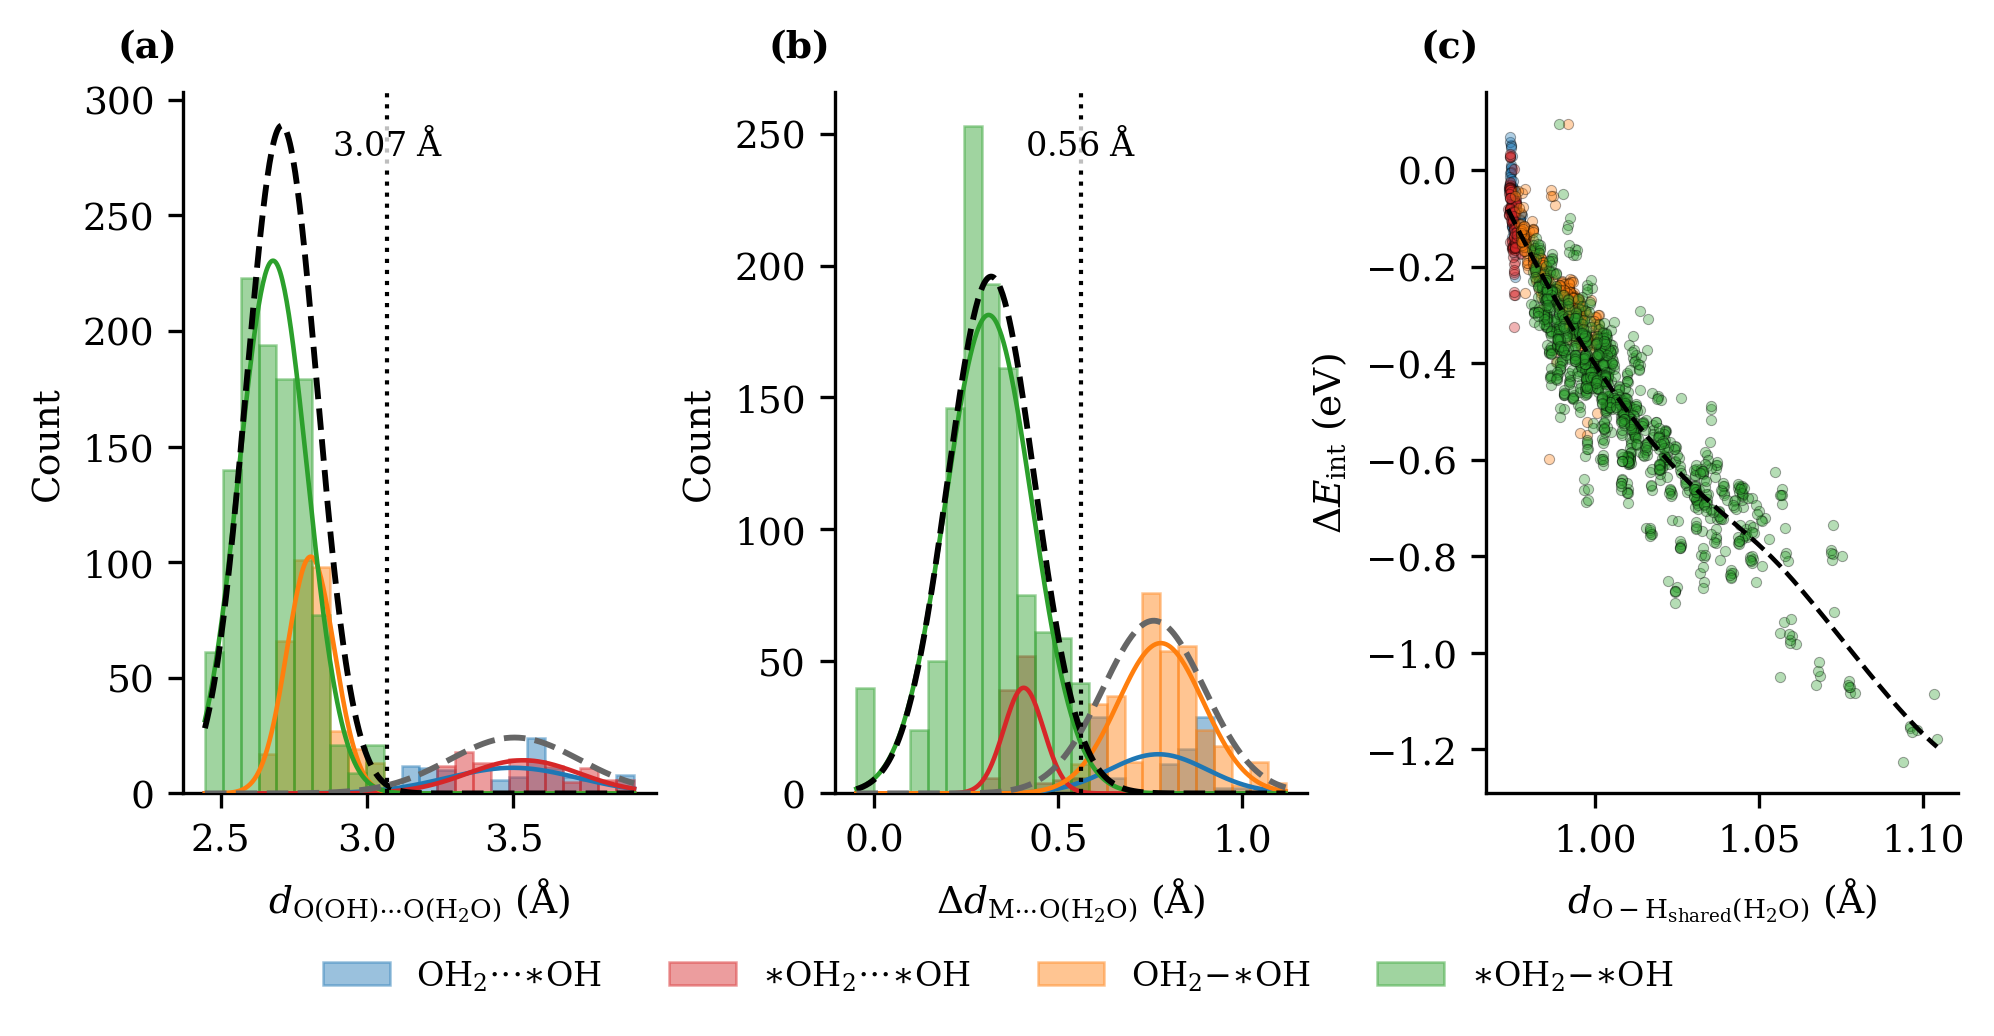

In [29]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(17/2.54, FIG_WIDTH_IN),
)

gmm_group_overlay(
    axes[0],
    df,
    "d_O_O",
    r"$d_\mathrm{O(OH)\cdots O(H_2O)}$ ($\mathrm{\AA}$)",
)
gmm_group_overlay(
    axes[1],
    df,
    "d_O_H2O_M",
    r"$\Delta d_\mathrm{M\cdots O(H_2O)}$ ($\mathrm{\AA}$)",
)
water_oh_trend(axes[2], df)

for ax, label in zip(axes, ["(a)", "(b)", "(c)"]):
    add_panel_label(ax, label, a=0.04)

finalize_multipanel_figure(
    fig,
    axes[0],
    17/2.54,
    FIG_WIDTH_IN,
    ncols=4,
)
fig.subplots_adjust(wspace=0.38)
#Spearman’s rank correlation coefficient
save_figure(fig, "Figure2_geometric_classification_OH_dependence")
plt.show()


## Figure SI3 · Smoothed probability-density surface 


Written: analysis_outputs/FigureSI3_joint_geometry_probability_density_3D.pdf


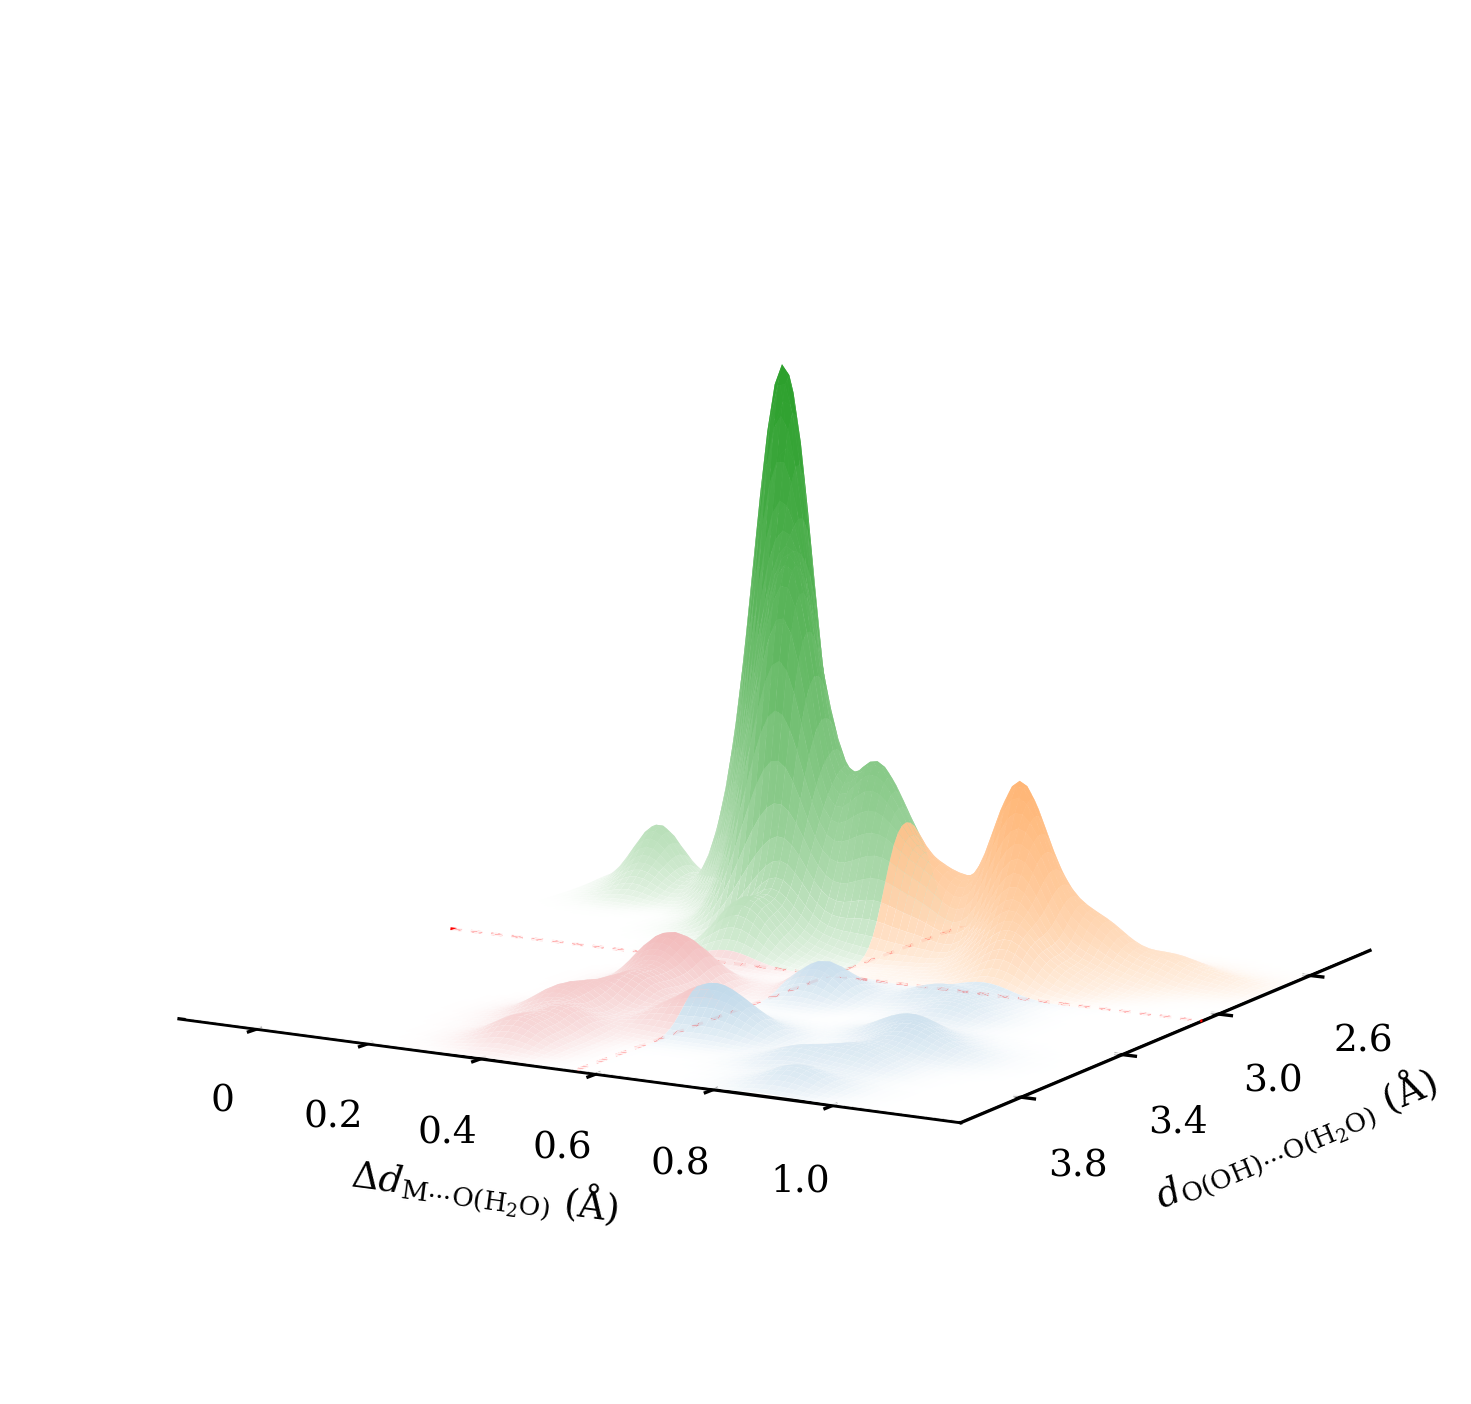

In [30]:
# =========================================================
# Figure SI2: smoothed joint distance distribution
# =========================================================

from scipy.ndimage import gaussian_filter
from matplotlib.colors import LogNorm

# ---------------- Adjustable settings ----------------
SMOOTH_SIGMA = 3.0      # In bins: larger = smoother; 0 = no smoothing
N_BINS = 100
DENSITY_FLOOR = 0.005   # Display cutoff relative to maximum density
N_CONTOUR_LEVELS = 40
# -----------------------------------------------------

xcol = "d_O_O"
ycol = "d_O_H2O_M"

# Pool all finite distance pairs independently of class labels.
valid = np.isfinite(
    df[[xcol, ycol]].to_numpy(dtype=float)
).all(axis=1)
joint_data = df.loc[valid, [xcol, ycol]].copy()

if joint_data.empty:
    raise ValueError("No structures with finite distance pairs.")
if SMOOTH_SIGMA < 0:
    raise ValueError("SMOOTH_SIGMA must be nonnegative.")

threshold_x = GMM_THRESHOLDS[xcol]
threshold_y = GMM_THRESHOLDS[ycol]


def padded_limits(values, fraction=0.08):
    lo, hi = np.min(values), np.max(values)
    padding = max((hi - lo) * fraction, 0.05)
    return lo - padding, hi + padding


xlim = padded_limits(joint_data[xcol].to_numpy())
ylim = padded_limits(joint_data[ycol].to_numpy())

counts, xedges, yedges = np.histogram2d(
    joint_data[xcol],
    joint_data[ycol],
    bins=N_BINS,
    range=[xlim, ylim],
)

# Smooth the pooled histogram and normalize its integral to one.
smoothed = gaussian_filter(
    counts.astype(float),
    sigma=SMOOTH_SIGMA,
    mode="constant",
)

dx = np.diff(xedges)[0]
dy = np.diff(yedges)[0]
density = smoothed / (smoothed.sum() * dx * dy)

xcenters = (xedges[:-1] + xedges[1:]) / 2
ycenters = (yedges[:-1] + yedges[1:]) / 2

vmax = density.max()
vmin = vmax * DENSITY_FLOOR
levels = np.geomspace(vmin, vmax, N_CONTOUR_LEVELS)

# =========================================================
# 3D view of the smoothed joint probability density
# =========================================================

ELEVATION = 10
AZIMUTH = 30

from matplotlib.colors import to_rgb


X, Y = np.meshgrid(xcenters, ycenters)
Z = density.T


# =========================================================
# Quadrant-specific colors
# =========================================================

# Assign quadrants using the existing geometry thresholds.
close_oh = X <= threshold_x
close_metal = Y <= threshold_y

quadrant_masks = [
    ~close_oh & ~close_metal,  # Distant water
    ~close_oh & close_metal,   # Metal only
    close_oh & ~close_metal,   # H-bond only
    close_oh & close_metal,    # Resonance-ON
]

# Shared density-to-color scaling across all quadrants.
#
# gamma < 1:
#     low-density regions become colorful more quickly
#
# gamma = 1:
#     linear white -> group color
#
# gamma > 1:
#     low-density regions remain whiter
COLOR_GAMMA = 0.5

strength = np.clip(Z / Z.max(), 0, 1) ** COLOR_GAMMA

# Start from white RGBA.
facecolors = np.ones((*Z.shape, 4))

for mask, group in zip(quadrant_masks, H2O_ENV_ORDER):
    color = np.asarray(to_rgb(env_color(group)))

    # White -> corresponding group color according to density.
    facecolors[mask, :3] = (
        1 - strength[mask, None] * (1 - color)
    )

facecolors[..., 3] = 0.95


# =========================================================
# Plot
# =========================================================

fig = plt.figure(figsize=(FIG_WIDTH_IN*2, FIG_WIDTH_IN*1.5))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    X,
    Y,
    Z,
    facecolors=facecolors,
    rcount=Z.shape[0],
    ccount=Z.shape[1],
    linewidth=0,
    antialiased=True,
    shade=False,
)

ax.set_xlabel(
    r"$d_{\mathrm{O(OH)\cdots O(H_2O)}}$ ($\mathrm{\AA}$)",
    labelpad=10,
)
ax.set_ylabel(
    r"$\Delta d_{\mathrm{M\cdots O(H_2O)}}$ ($\mathrm{\AA}$)",
    labelpad=10,
)
ax.set_zlabel(
    r"Probability density ($\mathrm{\AA}^{-2}$)",
    labelpad=10,
)


# =========================================================
# Threshold lines
# =========================================================

threshold_style = dict(
    color="red",
    linestyle=(0, (4, 3)),
    linewidth=0.7,
    alpha=1.0,
    dash_capstyle="butt",
)

ax.plot(
    [threshold_x, threshold_x],
    [ylim[0], ylim[1]],
    [0, 0],
    **threshold_style,
)

ax.plot(
    [xlim[0], xlim[1]],
    [threshold_y, threshold_y],
    [0, 0],
    **threshold_style,
)


# =========================================================
# Axes
# =========================================================

ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_zlim(0, Z.max() * 1.05)

ax.set_xticks([2.6, 3.0, 3.4, 3.8])
ax.set_xticklabels(["2.6", "3.0", "3.4", "3.8"])

ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(["0", "0.2", "0.4", "0.6", "0.8", "1.0"])

ax.view_init(
    elev=ELEVATION,
    azim=AZIMUTH,
)

ax.set_box_aspect((1, 1, 0.7))

ax.grid(False)

for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.pane.fill = False
    axis.pane.set_edgecolor("none")


# =========================================================
# Hide z axis while retaining invisible ticks
# =========================================================

ax.set_zlabel("")
ax.zaxis.line.set_visible(False)

# Retain invisible ticks to avoid the empty-bounding-box error.
ax.set_zticks([0, Z.max()])

ax.tick_params(
    axis="z",
    colors=(0, 0, 0, 0),
    labelcolor=(0, 0, 0, 0),
)


fig.subplots_adjust(
    left=0.0,
    right=0.9,
    bottom=0.08,
    top=1.0,
)

ax.xaxis.labelpad = 4
ax.yaxis.labelpad = 4

# Fractions removed from the existing tight bounding box.
CROP_TOP = 0.20
CROP_BOTTOM = 0.08
CROP_LEFT = 0.06
CROP_RIGHT = 0.00

from matplotlib.transforms import Bbox

fig.canvas.draw()
bbox = fig.get_tightbbox(fig.canvas.get_renderer())

cropped_bbox = Bbox.from_extents(
    bbox.x0 + CROP_LEFT * bbox.width,
    bbox.y0 + CROP_BOTTOM * bbox.height,
    bbox.x1 - CROP_RIGHT * bbox.width,
    bbox.y1 - CROP_TOP * bbox.height,
)

output_path = (
    OUTPUT_DIR / "FigureSI3_joint_geometry_probability_density_3D.pdf"
)
fig.savefig(
    output_path,
    bbox_inches=cropped_bbox,
    dpi=600,
    facecolor="white",
)

print(f"Written: {output_path}")
plt.show()

## Figure 3 · Nonadditive stabilization


written: analysis_outputs/Figure3_nonadditive_stabilization.pdf


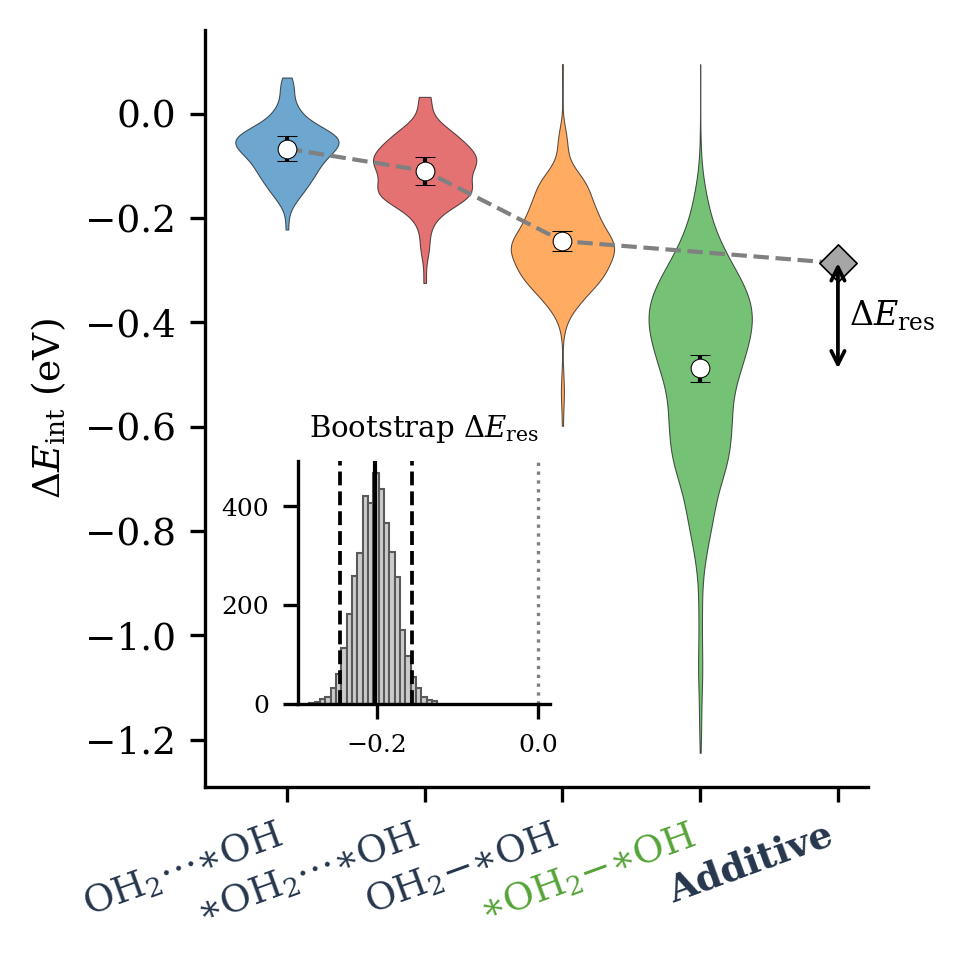

,Environment,n_structures,mean_Eint_eV,CI95_low_eV,CI95_high_eV
0,1 H2O far from both OH and metal,102,-0.0673,-0.0901,-0.0435
1,2 H2O close to metal only,112,-0.1096,-0.1363,-0.0833
2,3 H2O close to OH only,341,-0.2444,-0.2632,-0.2258
3,4 H2O close to both OH and metal,1104,-0.4886,-0.5138,-0.4633


Number of substitution families: 294
Valid cluster-bootstrap replicates: 4000
Additive expectation: -0.2867 eV
E_res: -0.2019 eV (family-cluster bootstrap 95% CI: -0.2465, -0.1570 eV)


In [31]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ---------------------------------------------------------------------
# Structure-level distributions and point estimates
# ---------------------------------------------------------------------

structure_values = [
    df.loc[
        df["h2o_env"].astype(str).eq(str(group)),
        "E_interaction",
    ].to_numpy(dtype=float)
    for group in H2O_ENV_ORDER
]
structure_values = [v[np.isfinite(v)] for v in structure_values]

if any(len(v) == 0 for v in structure_values):
    raise ValueError("All four environments must contain valid energies.")

# Point estimates remain structure-level means.
structure_means = np.array([v.mean() for v in structure_values])

structure_additive = (
    structure_means[1]
    + structure_means[2]
    - structure_means[0]
)
structure_eres = structure_means[3] - structure_additive


# ---------------------------------------------------------------------
# Family-cluster bootstrap
# ---------------------------------------------------------------------

bootstrap_df = (
    df[["family", "h2o_env", "E_interaction"]]
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["family", "h2o_env", "E_interaction"])
    .copy()
)

families = bootstrap_df["family"].unique()

# Store row indices belonging to each family.
family_to_idx = {
    family: np.flatnonzero(
        bootstrap_df["family"].to_numpy() == family
    )
    for family in families
}

rng_cluster = np.random.default_rng(RANDOM_STATE)

cluster_boot_means = []
cluster_boot_eres = []

for _ in range(N_BOOTSTRAP):

    # Resample complete families.
    sampled_families = rng_cluster.choice(
        families,
        size=len(families),
        replace=True,
    )

    sampled_idx = np.concatenate([
        family_to_idx[family]
        for family in sampled_families
    ])

    sample = bootstrap_df.iloc[sampled_idx]

    means = np.array([
        sample.loc[
            sample["h2o_env"].astype(str).eq(str(group)),
            "E_interaction",
        ].mean()
        for group in H2O_ENV_ORDER
    ])

    # Extremely unlikely, but reject a replicate if one environment
    # happens to be absent after cluster resampling.
    if not np.isfinite(means).all():
        continue

    cluster_boot_means.append(means)

    eres = (
        means[3]
        - means[1]
        - means[2]
        + means[0]
    )
    cluster_boot_eres.append(eres)

cluster_boot_means = np.asarray(cluster_boot_means)
cluster_boot_eres = np.asarray(cluster_boot_eres)

cluster_ci = np.percentile(
    cluster_boot_means,
    [2.5, 97.5],
    axis=0,
)

cluster_eres_ci = np.percentile(
    cluster_boot_eres,
    [2.5, 97.5],
)


# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(FIG_WIDTH_IN, FIG_WIDTH_IN)
)

violins = ax.violinplot(
    structure_values,
    positions=np.arange(4),
    widths=0.75,
    showmeans=False,
    showmedians=False,
    showextrema=False,
    points=200,
    bw_method="scott",
)

for body, group in zip(
    violins["bodies"],
    H2O_ENV_ORDER,
):
    body.set_facecolor(env_color(group))
    body.set_edgecolor("black")
    body.set_linewidth(MPL_EDGE_WIDTH)
    body.set_alpha(0.65)


# Structure-level mean + family-cluster-bootstrap CI.
for i, mean in enumerate(structure_means):

    lo, hi = cluster_ci[:, i]

    ax.plot(
        [i, i],
        [lo, hi],
        color="black",
        lw=1.0,
        solid_capstyle="butt",
        zorder=5,
    )

    ax.plot(
        [i, i],
        [lo, hi],
        linestyle="none",
        marker="_",
        markersize=5,
        color="black",
        zorder=5,
    )

    ax.plot(
        i,
        mean,
        marker="o",
        linestyle="none",
        mfc="white",
        mec="black",
        ms=4.5,
        zorder=6,
    )


# ---------------------------------------------------------------------
# Additive expectation and E_res
# ---------------------------------------------------------------------

x_add = 4
observed_structure = structure_means[3]

ax.plot(
    [0, 1, 2, x_add],
    [
        *structure_means[:3],
        structure_additive,
    ],
    color="0.5",
    lw=1.0,
    ls="--",
    zorder=1,
)

ax.scatter(
    x_add,
    structure_additive,
    s=40,
    facecolor="0.65",
    edgecolor="black",
    linewidth=0.4,
    marker="D",
    zorder=3,
)

ax.annotate(
    "",
    xy=(x_add, observed_structure),
    xytext=(x_add, structure_additive),
    arrowprops=dict(
        arrowstyle="<->",
        lw=0.9,
        color="black",
        shrinkA=0,
        shrinkB=0,
    ),
    zorder=4,
)

ax.text(
    x_add + 0.08,
    (
        structure_additive
        + observed_structure
    ) / 2,
    r"$\Delta E_{\mathrm{res}}$",
    fontsize=MPL_FONT_SIZE,
    ha="left",
    va="center",
)


# ---------------------------------------------------------------------
# Axes
# ---------------------------------------------------------------------

ax.set_xticks(range(5))
ax.set_xticklabels(
    [
        env_label(g)
        for g in H2O_ENV_ORDER
    ] + ["Additive"],
    rotation=20,
    ha="right",
)

ax.set_ylabel(r"$\Delta E_{\mathrm{int}}$ (eV)")

ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(direction="out")

for i, label in enumerate(ax.get_xticklabels()):
    label.set_color(
        "#55A438"
        if i == 3
        else "#26364D"
    )
    label.set_fontweight("bold")

fig.tight_layout()


# ---------------------------------------------------------------------
# Family-cluster-bootstrap distribution of E_res
# ---------------------------------------------------------------------

axins = inset_axes(
    ax,
    width="38%",
    height="32%",
    loc="lower left",
    bbox_to_anchor=(0.14, 0.11, 1, 1),
    bbox_transform=ax.transAxes,
    borderpad=0,
)

axins.hist(
    cluster_boot_eres,
    bins=24,
    color="0.80",
    edgecolor="0.35",
    linewidth=0.5,
)

axins.axvline(
    structure_eres,
    color="black",
    lw=1.0,
)

for bound in cluster_eres_ci:
    axins.axvline(
        bound,
        color="black",
        lw=0.9,
        ls="--",
    )

axins.axvline(
    0,
    color="gray",
    lw=0.8,
    ls=":",
)

axins.set_title(
    r"Bootstrap $\Delta E_{\mathrm{res}}$",
    fontsize=MPL_FONT_SIZE - 1,
)

axins.tick_params(
    direction="out",
    labelsize=MPL_FONT_SIZE - 2,
)

axins.spines[
    ["top", "right"]
].set_visible(False)


save_figure(
    fig,
    "Figure3_nonadditive_stabilization"
)

plt.show()


# ---------------------------------------------------------------------
# Numerical summary
# ---------------------------------------------------------------------

display(
    pd.DataFrame({
        "Environment": H2O_ENV_ORDER,
        "n_structures": [
            len(v)
            for v in structure_values
        ],
        "mean_Eint_eV": structure_means,
        "CI95_low_eV": cluster_ci[0],
        "CI95_high_eV": cluster_ci[1],
    }).round(4)
)

print(
    f"Number of substitution families: "
    f"{len(families)}"
)

print(
    f"Valid cluster-bootstrap replicates: "
    f"{len(cluster_boot_eres)}"
)

print(
    f"Additive expectation: "
    f"{structure_additive:.4f} eV"
)

print(
    f"E_res: {structure_eres:.4f} eV "
    f"(family-cluster bootstrap 95% CI: "
    f"{cluster_eres_ci[0]:.4f}, "
    f"{cluster_eres_ci[1]:.4f} eV)"
)

## Figure 4 · Metal and bridge effects


written: analysis_outputs/Figure4_metal_bridge_effects.pdf


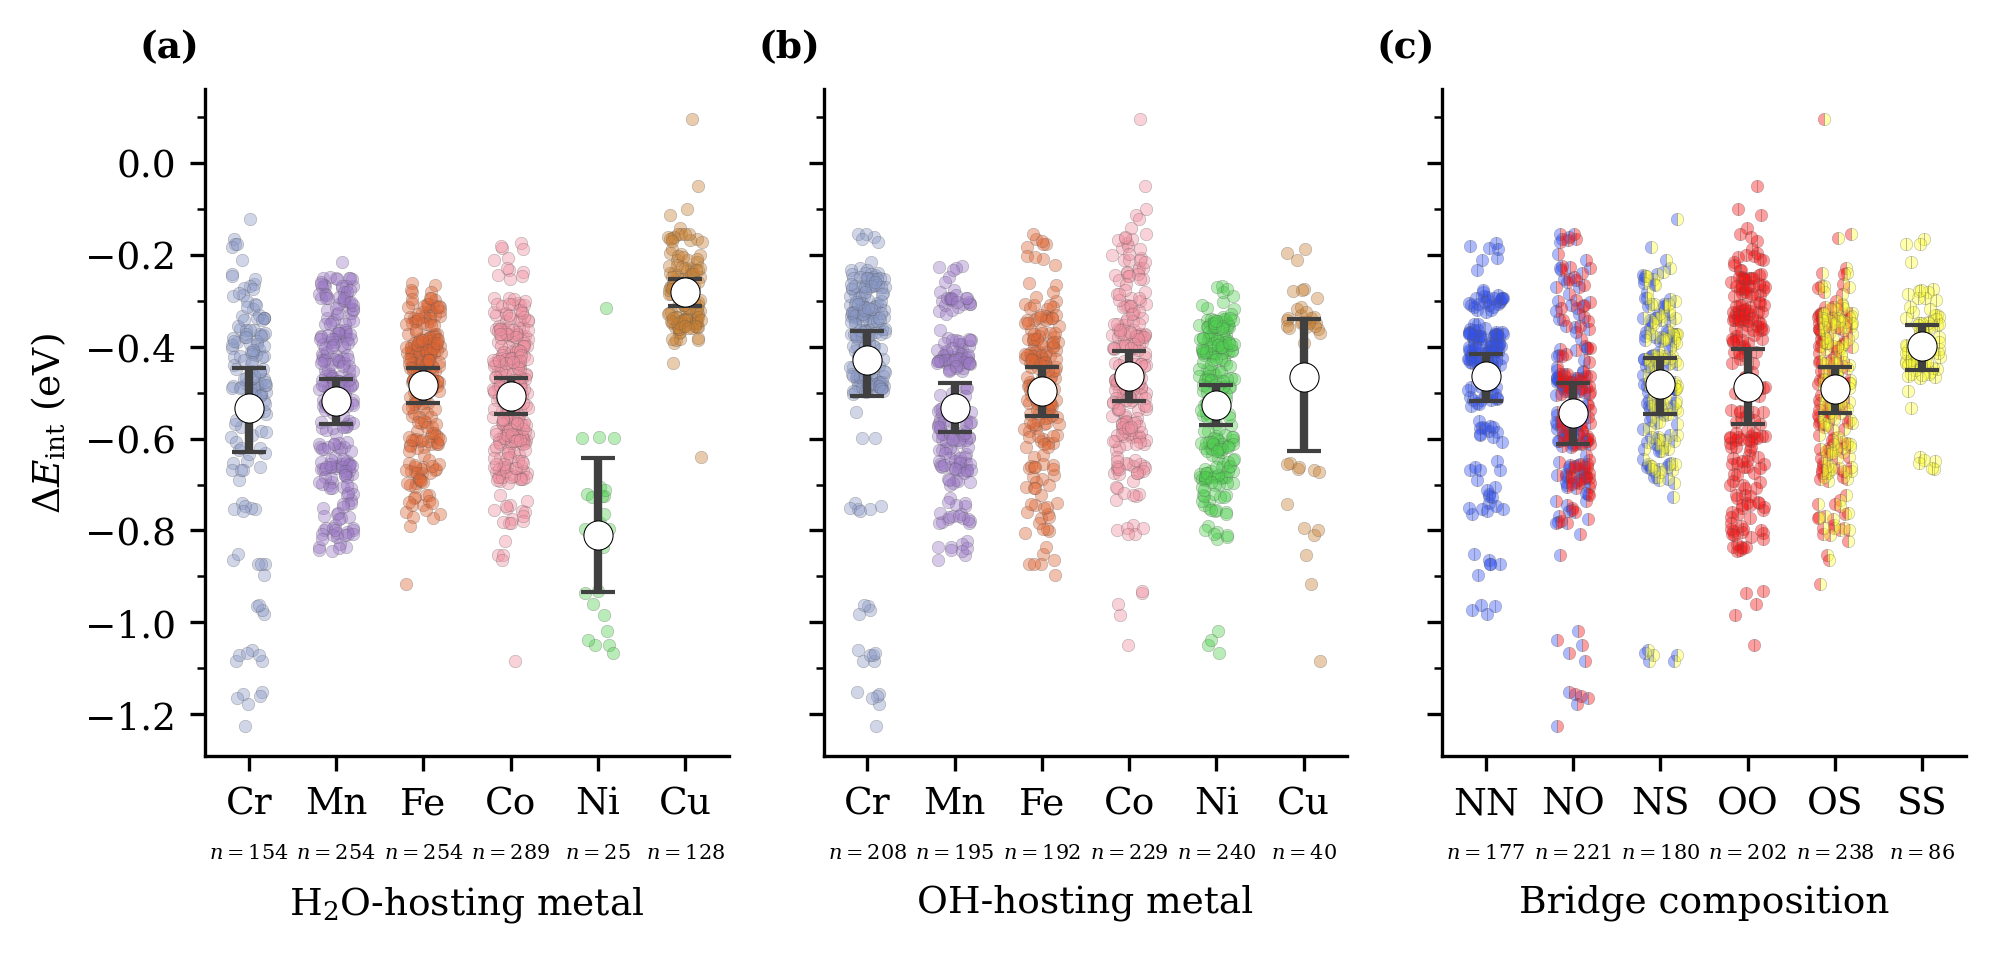

In [38]:
from ase.data import atomic_numbers
from ase.data.colors import jmol_colors
from matplotlib.ticker import MultipleLocator

JITTER_WIDTH = 0.20
POINT_SIZE = 9
POINT_ALPHA = 0.40

rng_jitter = np.random.default_rng(RANDOM_STATE)


def element_color(symbol):
    return jmol_colors[atomic_numbers[symbol]]


on_data = df.loc[
    df["h2o_env"].eq(H2O_ENV_ORDER[3])
    & np.isfinite(df["E_interaction"])
].copy()

# OH-hosting metal: structure means and family-cluster bootstrap CIs.
if on_data["family"].isna().any():
    raise ValueError("Missing family labels in the Resonance-ON subset.")

rng_oh = np.random.default_rng(RANDOM_STATE)
oh_results = []

for metal, group in on_data.groupby("oh_metal"):
    family_stats = group.groupby("family")["E_interaction"].agg(
        ["sum", "count"]
    )
    family_sums = family_stats["sum"].to_numpy()
    family_counts = family_stats["count"].to_numpy()
    n_families = len(family_stats)

    # Resample whole families; retain structure weighting within replicates.
    sampled = rng_oh.integers(
        0, n_families,
        size=(N_BOOTSTRAP, n_families),
    )
    bootstrap_means = (
        family_sums[sampled].sum(axis=1)
        / family_counts[sampled].sum(axis=1)
    )
    lo, hi = np.percentile(bootstrap_means, [2.5, 97.5])

    oh_results.append({
        "level": metal,
        "mean_eV": group["E_interaction"].mean(),
        "ci_lo": lo,
        "ci_hi": hi,
    })

by_oh_metal_dp = pd.DataFrame(oh_results)

metal_order = sorted(
    by_metal_dp["level"].tolist(),
    key=atomic_numbers.__getitem__,
)
oh_metal_order = sorted(
    by_oh_metal_dp["level"].tolist(),
    key=atomic_numbers.__getitem__,
)
bridge_order = sorted(
    by_bridge_dp["level"].tolist(),
    key=lambda bridge: tuple(atomic_numbers[symbol] for symbol in bridge),
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(17 / 2.54, FIG_WIDTH_IN),
    sharey=True,
)

for ax, table, title, column, order in [
    (
        axes[0], by_metal_dp,
        r"H$_2$O-hosting metal", "h2o_metal", metal_order,
    ),
    (
        axes[2], by_bridge_dp,
        "Bridge composition", "bridge", bridge_order,
    ),
    (
        axes[1], by_oh_metal_dp,
        "OH-hosting metal", "oh_metal", oh_metal_order,
    ),
]:
    indexed = table.set_index("level")
    x = np.arange(len(order))
    counts = on_data[column].value_counts()

    for xi, level in zip(x, order):
        values = on_data.loc[
            on_data[column].eq(level), "E_interaction"
        ].to_numpy()

        jittered_x = xi + rng_jitter.uniform(
            -JITTER_WIDTH, JITTER_WIDTH, size=len(values)
        )

        # Individual structures behind the means and confidence intervals.
        if column == "bridge":
            ax.plot(
                jittered_x,
                values,
                linestyle="none",
                marker="o",
                fillstyle="left",
                markerfacecolor=element_color(level[0]),
                markerfacecoloralt=element_color(level[1]),
                markeredgecolor="0.35",
                markeredgewidth=0.15,
                markersize=np.sqrt(POINT_SIZE),
                alpha=POINT_ALPHA,
                zorder=1,
            )
        else:
            ax.scatter(
                jittered_x,
                values,
                s=POINT_SIZE,
                facecolor=element_color(level),
                edgecolor="0.35",
                linewidth=0.15,
                alpha=POINT_ALPHA,
                zorder=1,
            )

        if level not in indexed.index:
            continue

        row = indexed.loc[level]
        if not np.isfinite(row["mean_eV"]):
            continue

        # Family-cluster bootstrap confidence intervals.
        ax.plot(
            [xi, xi],
            [row["ci_lo"], row["ci_hi"]],
            color="0.25",
            solid_capstyle="butt",
            lw=MPL_LINE_WIDTH * 2,
            zorder=3,
        )
        ax.plot(
            [xi, xi],
            [row["ci_lo"], row["ci_hi"]],
            linestyle="none",
            marker="_",
            markersize=8,
            markeredgewidth=MPL_LINE_WIDTH,
            color="0.25",
            zorder=3,
        )

        # White mean markers for every category.
        ax.plot(
            xi,
            row["mean_eV"],
            marker="o",
            linestyle="none",
            markerfacecolor="white",
            markeredgecolor="black",
            markeredgewidth=MPL_EDGE_WIDTH,
            markersize=MPL_MARKER_SIZE,
            zorder=4,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(order)

    for xi, level in zip(x, order):
        ax.text(
            xi, -0.13,
            f"$n={int(counts.get(level, 0))}$",
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="top",
            fontsize=MPL_FONT_SIZE - 3,
            clip_on=False,
        )

    ax.set_xlabel(title, labelpad=15)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(direction="out")
    ax.set_xlim(-0.5, len(order) - 0.5)

axes[0].set_ylabel(r"$\Delta E_{\mathrm{int}}$ (eV)")

# Include all individual values and confidence intervals without clipping.
plotted_tables = [by_metal_dp, by_bridge_dp, by_oh_metal_dp]
y_values = np.concatenate(
    [on_data["E_interaction"].to_numpy()]
    + [
        table[["ci_lo", "ci_hi"]].to_numpy().ravel()
        for table in plotted_tables
    ]
)
y_values = y_values[np.isfinite(y_values)]
padding = max(0.05 * np.ptp(y_values), 0.03)
axes[0].set_ylim(y_values.min() - padding, y_values.max() + padding)

axes[0].yaxis.set_major_locator(MultipleLocator(0.2))
axes[0].yaxis.set_minor_locator(MultipleLocator(0.1))

for ax, label in zip(axes, ["(a)", "(b)", "(c)"]):
    add_panel_label(ax, label, a=0.025)

fig.tight_layout()
save_figure(
    fig,
    "Figure4_metal_bridge_effects",
)
plt.show()

## Figure SI2 · Acid effects


written: analysis_outputs/FigureSI2_acid_substituent_effects.pdf


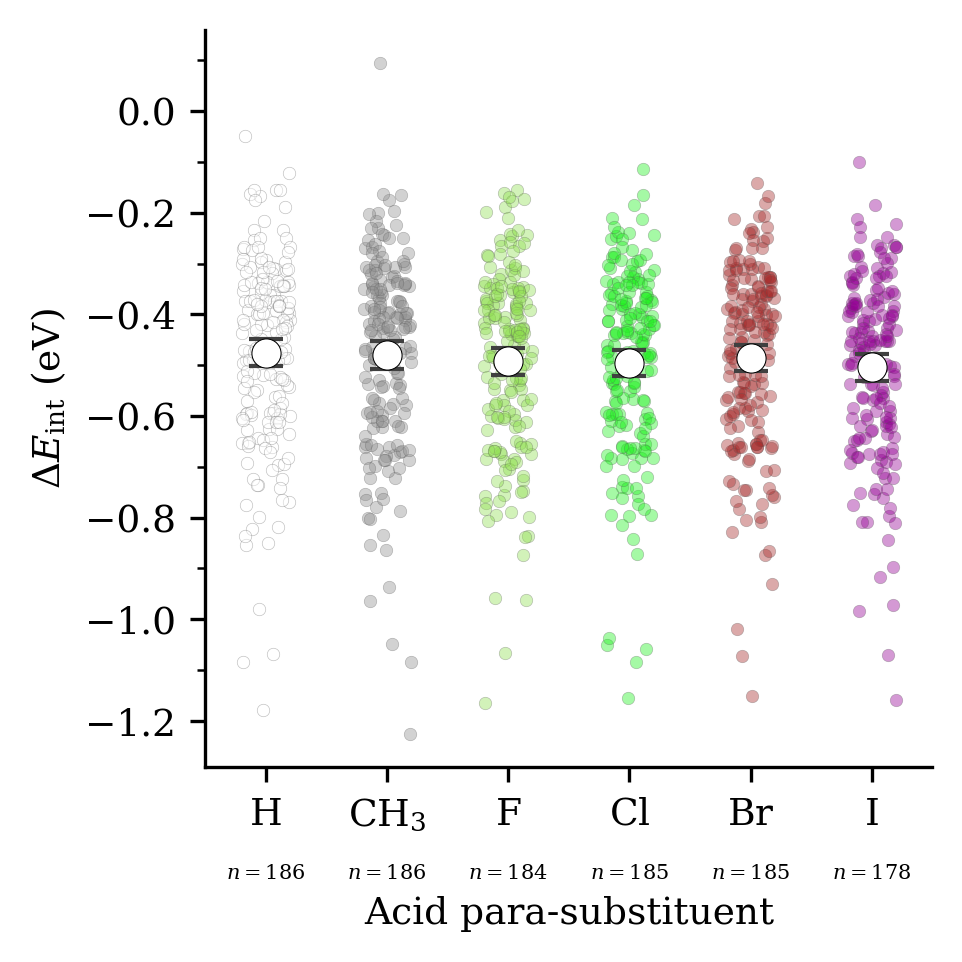

In [33]:
# Acid fragment -> para-substituent mapping
acid_map = {
    "A2": "H",
    "A1": "CH3",
    "A9": "F",
    "A4": "Cl",
    "A5": "Br",
    "A6": "I",
}

acid_order = ["A2", "A1", "A9", "A4", "A5", "A6"]

acid_element = {
    "A2": "H",
    "A1": "C",   # CH3
    "A9": "F",
    "A4": "Cl",
    "A5": "Br",
    "A6": "I",
}

rng_acid = np.random.default_rng(RANDOM_STATE)
acid_results = []

for acid, group in on_data.groupby("acid"):
    family_stats = group.groupby("family")["E_interaction"].agg(
        ["sum", "count"]
    )

    family_sums = family_stats["sum"].to_numpy()
    family_counts = family_stats["count"].to_numpy()
    n_families = len(family_stats)

    sampled = rng_acid.integers(
        0,
        n_families,
        size=(N_BOOTSTRAP, n_families),
    )

    bootstrap_means = (
        family_sums[sampled].sum(axis=1)
        / family_counts[sampled].sum(axis=1)
    )

    lo, hi = np.percentile(
        bootstrap_means,
        [2.5, 97.5],
    )

    acid_results.append({
        "level": acid,
        "mean_eV": group["E_interaction"].mean(),
        "ci_lo": lo,
        "ci_hi": hi,
    })

by_acid_dp = pd.DataFrame(acid_results)

acid_order_present = [
    acid
    for acid in acid_order
    if acid in by_acid_dp["level"].values
]

fig, ax = plt.subplots(
    1,
    1,
    figsize=(FIG_WIDTH_IN, FIG_WIDTH_IN),
)

indexed = by_acid_dp.set_index("level")
x = np.arange(len(acid_order_present))
counts = on_data["acid"].value_counts()

for xi, acid in zip(x, acid_order_present):
    values = on_data.loc[
        on_data["acid"].eq(acid),
        "E_interaction",
    ].to_numpy()

    jittered_x = xi + rng_jitter.uniform(
        -JITTER_WIDTH,
        JITTER_WIDTH,
        size=len(values),
    )

    ax.scatter(
        jittered_x,
        values,
        s=POINT_SIZE,
        facecolor=element_color(acid_element[acid]),
        edgecolor="0.35",
        linewidth=0.15,
        alpha=POINT_ALPHA,
        zorder=1,
    )

    row = indexed.loc[acid]

    ax.plot(
        [xi, xi],
        [row["ci_lo"], row["ci_hi"]],
        color="0.25",
        solid_capstyle="butt",
        lw=MPL_LINE_WIDTH * 2,
        zorder=3,
    )

    ax.plot(
        [xi, xi],
        [row["ci_lo"], row["ci_hi"]],
        linestyle="none",
        marker="_",
        markersize=8,
        markeredgewidth=MPL_LINE_WIDTH,
        color="0.25",
        zorder=3,
    )

    ax.plot(
        xi,
        row["mean_eV"],
        marker="o",
        linestyle="none",
        markerfacecolor="white",
        markeredgecolor="black",
        markeredgewidth=MPL_EDGE_WIDTH,
        markersize=MPL_MARKER_SIZE,
        zorder=4,
    )

ax.set_xticks(x)
ax.set_xticklabels(
    [
        rf"$\mathrm{{{acid_map[acid]}}}$"
        if acid_map[acid] != "CH3"
        else r"$\mathrm{CH_3}$"
        for acid in acid_order_present
    ]
)

for xi, acid in zip(x, acid_order_present):
    ax.text(
        xi,
        -0.13,
        f"$n={int(counts.get(acid, 0))}$",
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=MPL_FONT_SIZE - 3,
        clip_on=False,
    )

ax.set_xlabel(
    "Acid para-substituent",
    labelpad=15,
)
ax.set_ylabel(
    r"$\Delta E_{\mathrm{int}}$ (eV)"
)

ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(direction="out")
ax.set_xlim(-0.5, len(acid_order_present) - 0.5)

y_values = np.concatenate([
    on_data["E_interaction"].to_numpy(),
    by_acid_dp[["ci_lo", "ci_hi"]].to_numpy().ravel(),
])

y_values = y_values[np.isfinite(y_values)]

padding = max(
    0.05 * np.ptp(y_values),
    0.03,
)

ax.set_ylim(
    y_values.min() - padding,
    y_values.max() + padding,
)

ax.yaxis.set_major_locator(
    MultipleLocator(0.2)
)
ax.yaxis.set_minor_locator(
    MultipleLocator(0.1)
)

fig.tight_layout()

save_figure(
    fig,
    "FigureSI2_acid_substituent_effects",
)

plt.show()

## Figure SI4 · Water geometry, charge, and magnetic moment


written: analysis_outputs/FigureSI4_water_geometry_charge_magnetism.pdf


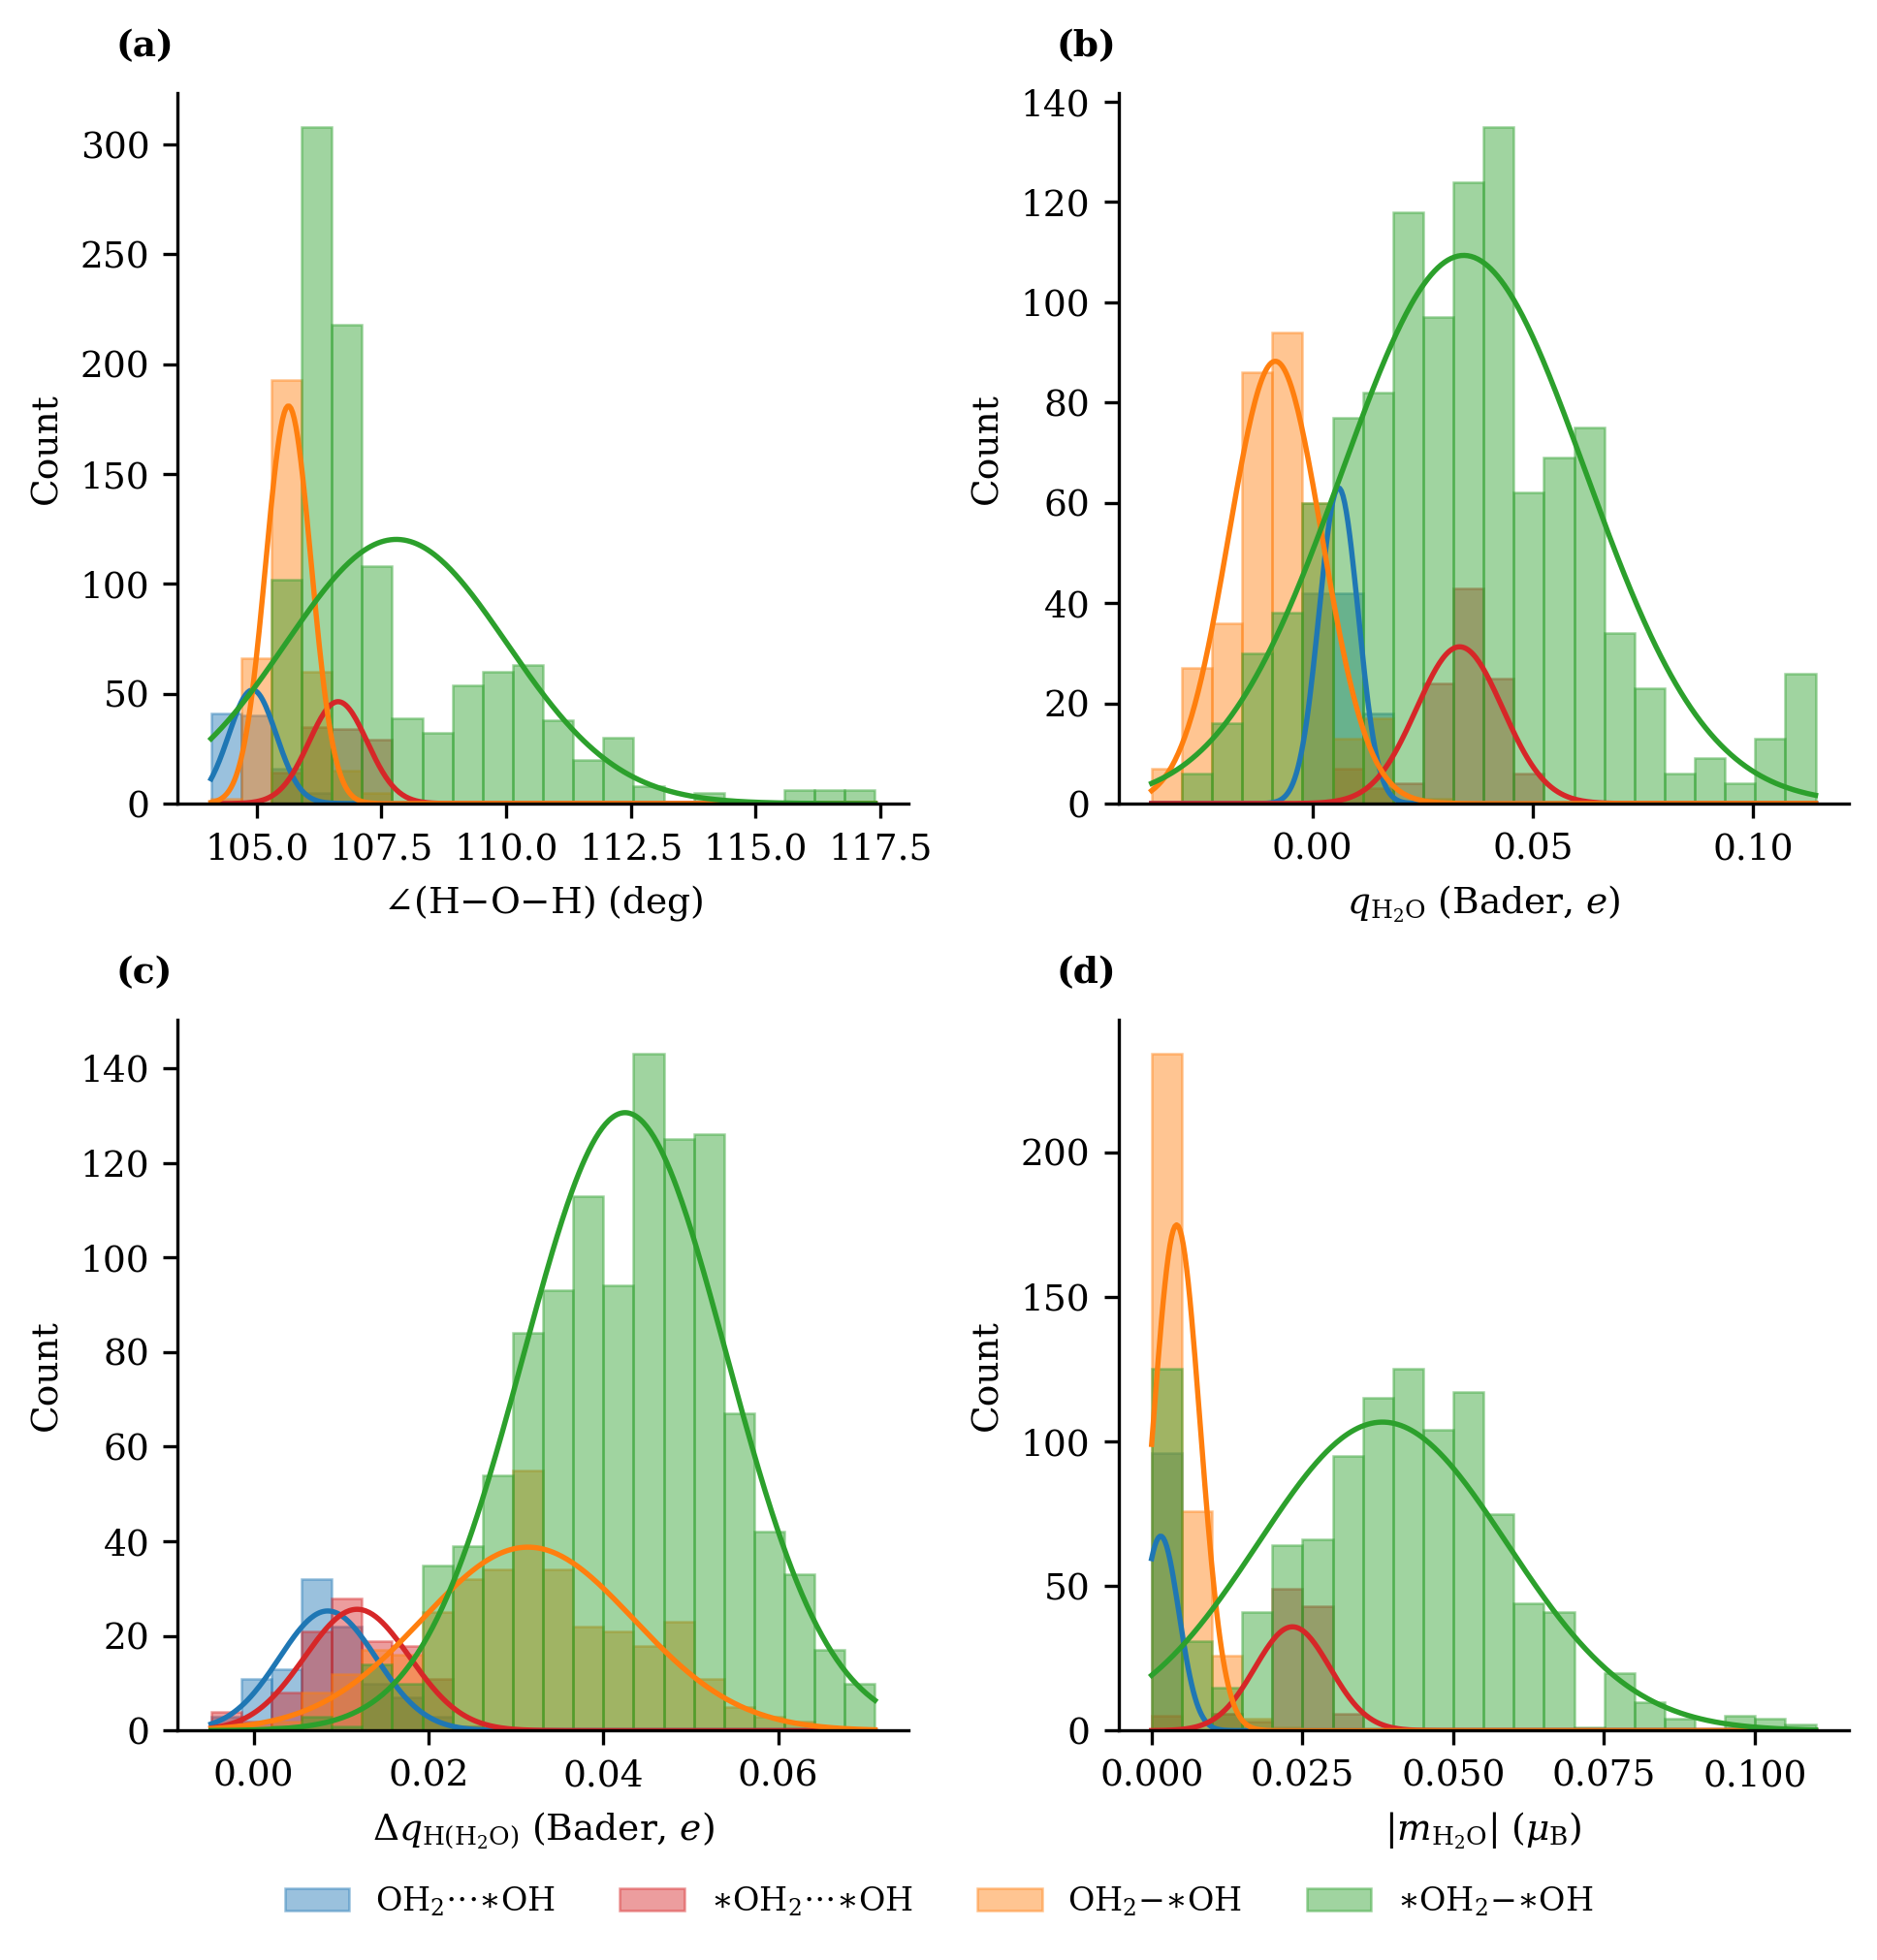

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(FIG_WIDTH_IN * 2, FIG_WIDTH_IN * 2))
for ax, column, xlabel, panel in zip(
    axes.flat,
    ["H2O_angle", "q_H2O", "q_Hbridge_minus_Hfree", "abs_h2o_magmom"],
    [r"$\angle$(H$-$O$-$H) (deg)",
     r"$q_{\mathrm{H_2O}}$ (Bader, $e$)",
     r"$\Delta q_{\mathrm{H(H_2O)}}$ (Bader, $e$)",
     r"$|m_{\mathrm{H_2O}}|$ ($\mu_\mathrm{B}$)"],
    ["(a)", "(b)", "(c)", "(d)"],
):
    hist_overlay(water_response_data, column, xlabel, bins=22, ax=ax, legend=False)
    add_panel_label(ax, panel, a=-0.015)
finalize_multipanel_figure(
    fig, axes[0, 0], FIG_WIDTH_IN * 2, FIG_WIDTH_IN * 2, ncols=4,
)
save_figure(fig, "FigureSI4_water_geometry_charge_magnetism")
plt.show()


## Figure SI5 · Matched water–metal distance differences


written: analysis_outputs/FigureSI5_matched_water_metal_distance.pdf


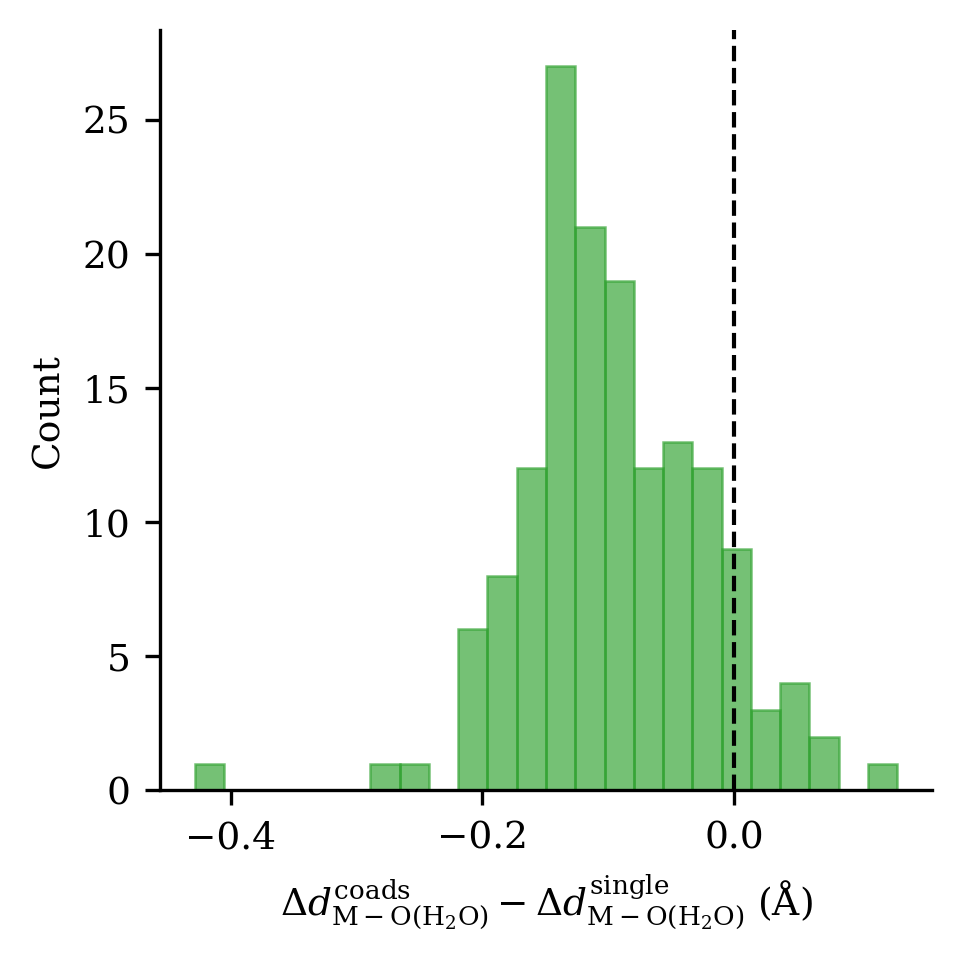

Valid pairs: 152
Mean difference:   -0.0957 Å
Median difference: -0.1041 Å
Shorter under coadsorption: 91.4%


In [35]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH_IN, FIG_WIDTH_IN))

ax.hist(
    differences,
    bins=24,
    density=False,
    color="#2ca02c",
    alpha=0.65,
    edgecolor="#2ca02c",
    linewidth=0.6,
)
ax.axvline(0, color="black", ls="--", lw=MPL_LINE_WIDTH)

ax.set_xlabel(
    r"$\Delta d_{\mathrm{M-O(H_2O)}}^{\mathrm{coads}}"
    r" - \Delta d_{\mathrm{M-O(H_2O)}}^{\mathrm{single}}$"
    r" ($\mathrm{\AA}$)"
)
ax.set_ylabel("Count")
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(direction="out")

fig.tight_layout()
save_figure(fig, "FigureSI5_matched_water_metal_distance")
plt.show()

print(f"Valid pairs: {len(differences)}")
print(f"Mean difference:   {differences.mean():.4f} Å")
print(f"Median difference: {np.median(differences):.4f} Å")
print(f"Shorter under coadsorption: {100 * (differences < 0).mean():.1f}%")


## Figure SI6 · Bare M–M versus coadsorbed O–O distances


written: analysis_outputs/FigureSI6_bare_MM_coadsorbed_OO.pdf


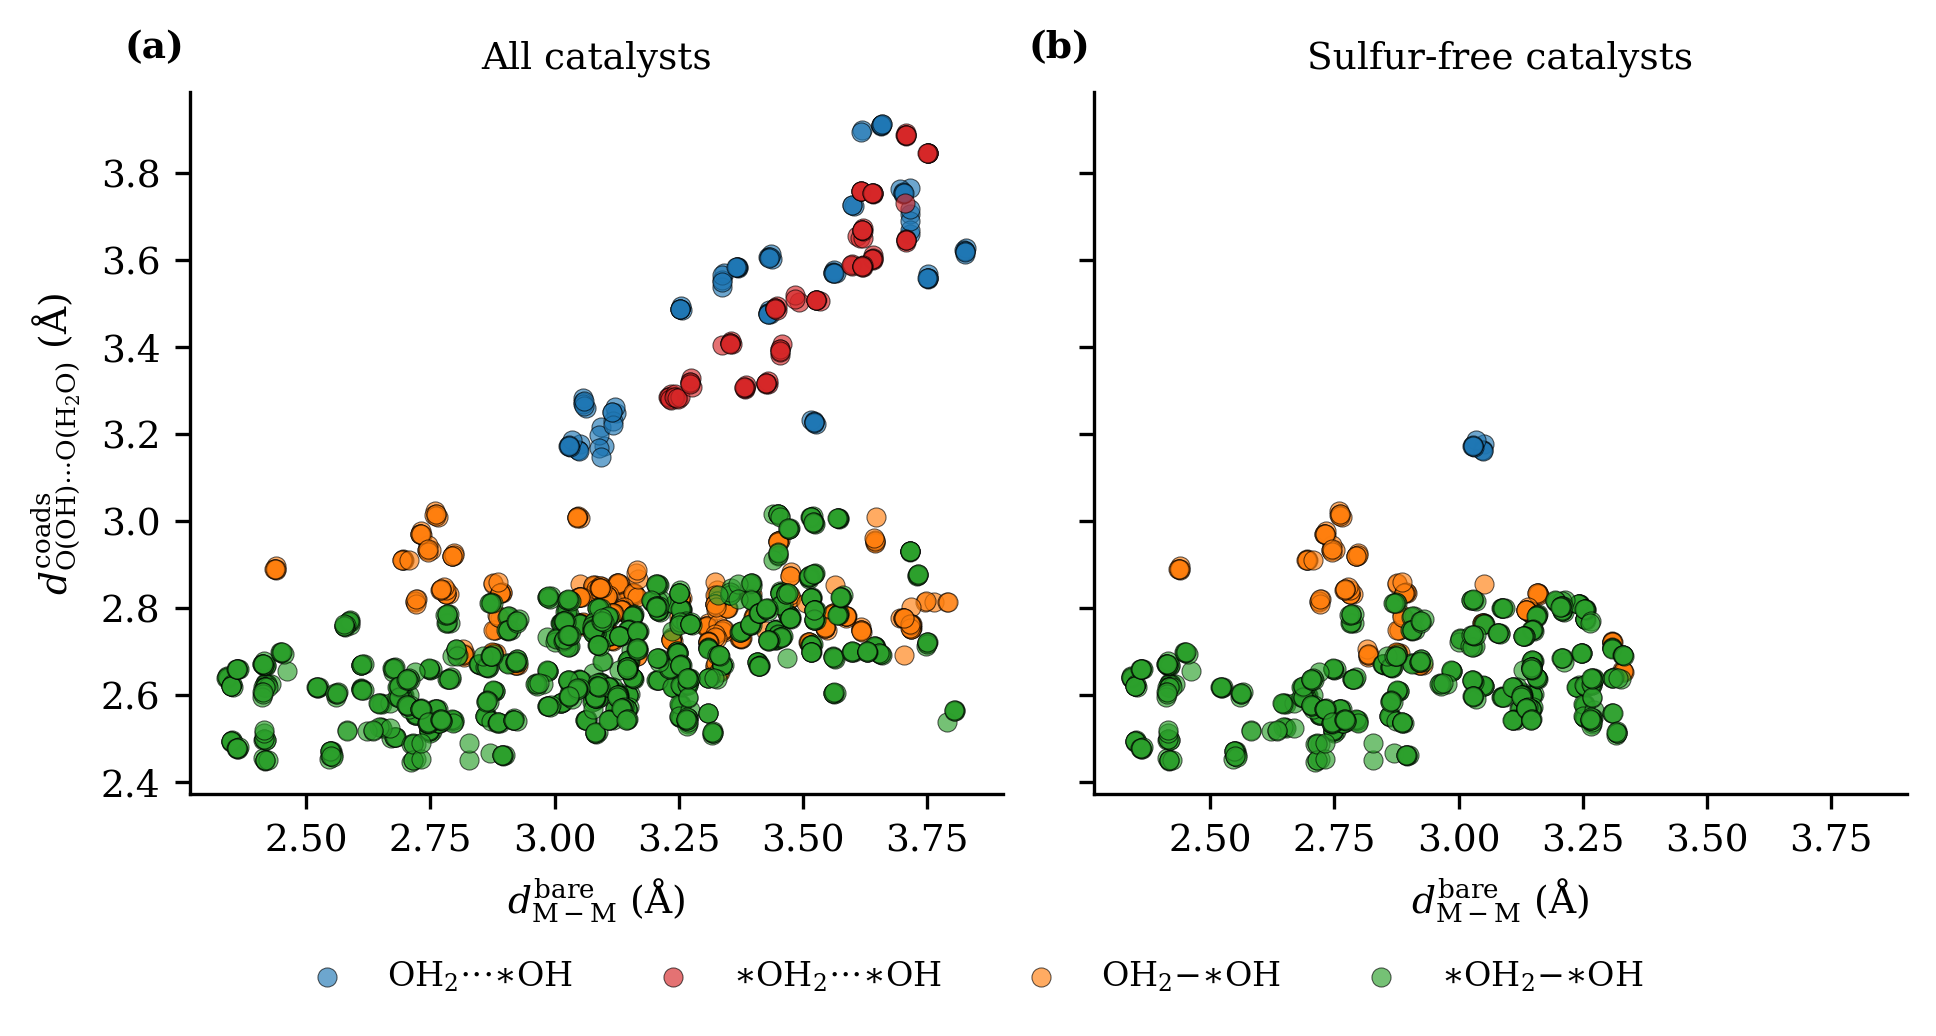

In [36]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(FIG_WIDTH_IN * 2.15, FIG_WIDTH_IN),
    sharex=True,
    sharey=True,
)

for ax, table, title, panel in [
    (axes[0], mm_oo, "All catalysts", "(a)"),
    (axes[1], sulfur_free, "Sulfur-free catalysts", "(b)"),
]:
    env = table["h2o_env"].astype(str)

    for group in H2O_ENV_ORDER:
        sub = table.loc[env.eq(str(group))]

        ax.scatter(
            sub["d_M_M_bare"],
            sub["d_O_O"],
            s=MPL_MARKER_SIZE*3,
            color=env_color(group),
            edgecolors="black",
            linewidths=MPL_EDGE_WIDTH,
            alpha=0.65,
            label=env_label(group),
            rasterized=True,
        )

    ax.set_xlabel(
        r"$d_{\mathrm{M-M}}^{\mathrm{bare}}$ ($\mathrm{\AA}$)"
    )
    ax.set_title(title, fontsize=MPL_LABEL_SIZE)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(direction="out")
    add_panel_label(ax, panel,a=-0.02)

axes[0].set_ylabel(
    r"$d_{\mathrm{O(OH)\cdots O(H_2O)}}^{\mathrm{coads}}$"
    r" ($\mathrm{\AA}$)"
)

finalize_multipanel_figure(
    fig,
    axes[0],
    FIG_WIDTH_IN*2,
    FIG_WIDTH_IN,
    ncols=4,
)

save_figure(fig, "FigureSI6_bare_MM_coadsorbed_OO")
plt.show()


## Figure SI7 · Bare-catalyst metal–metal distance distributions


written: analysis_outputs/FigureSI7_bare_metal_metal_distributions.pdf


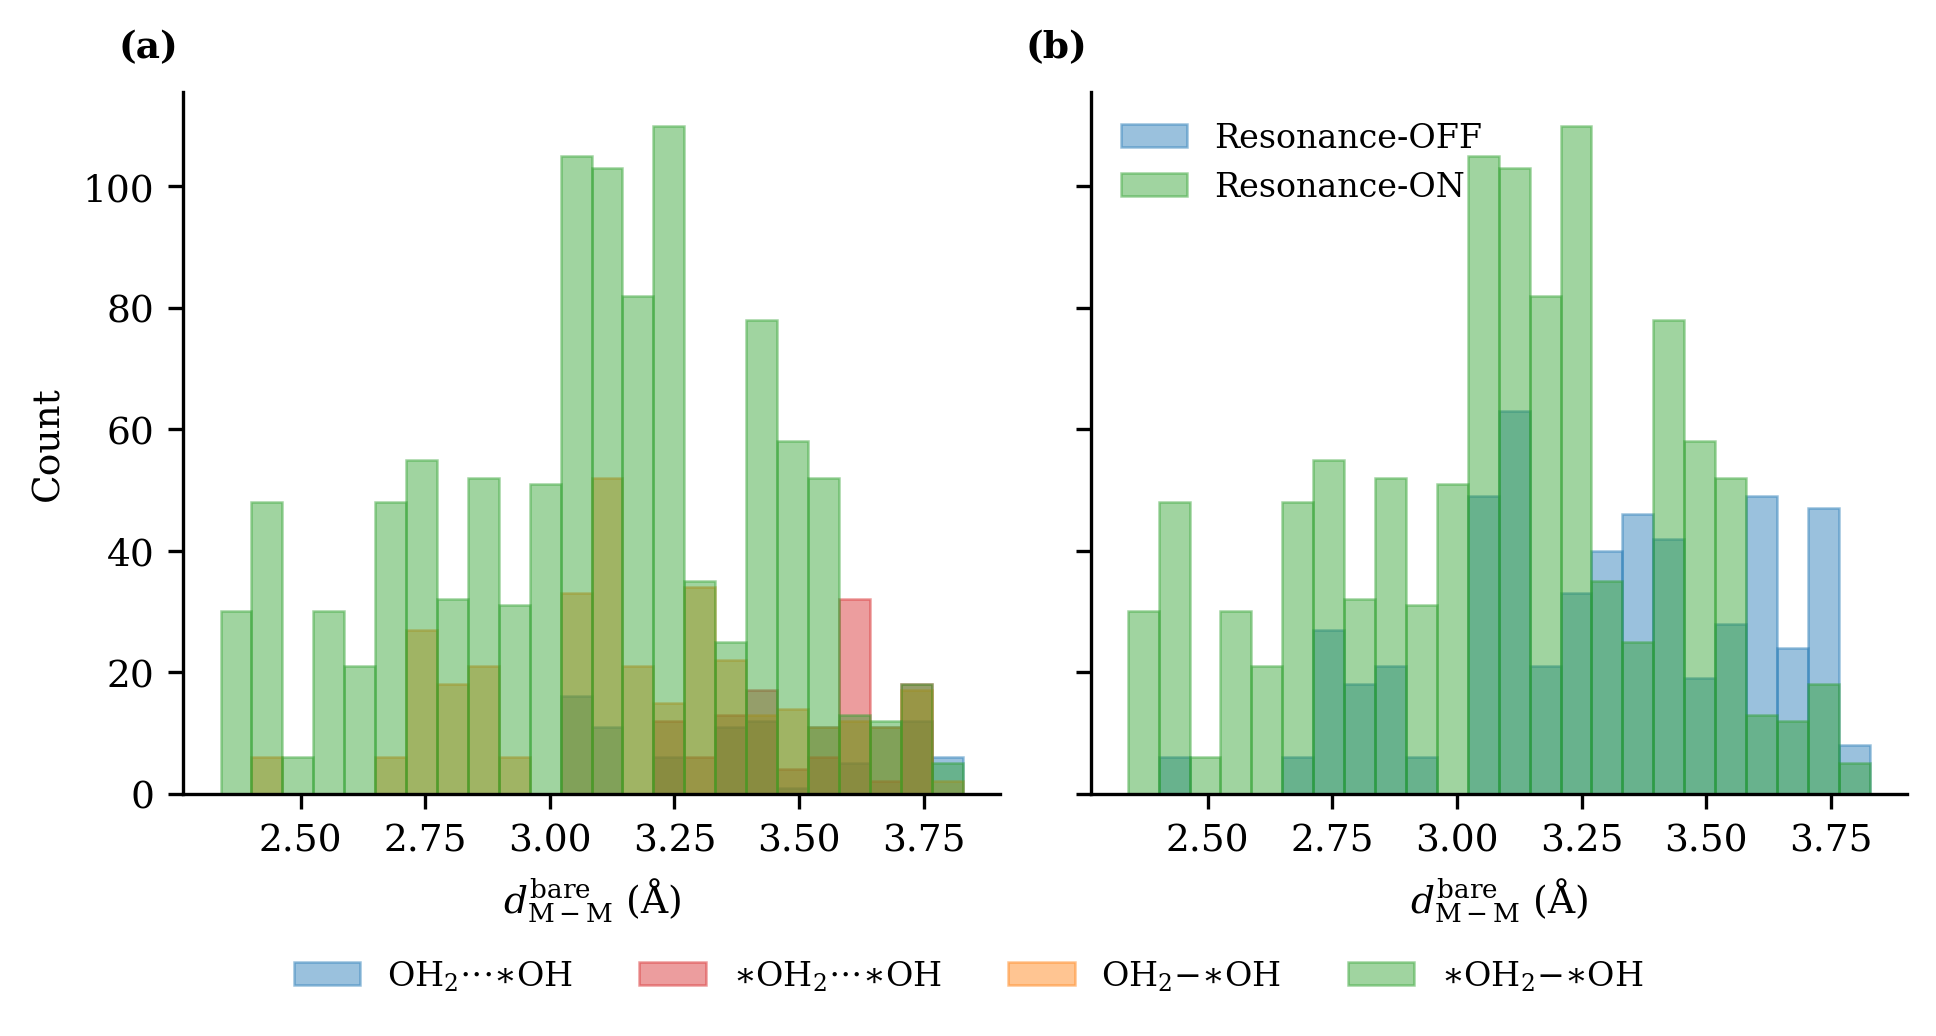

In [37]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(FIG_WIDTH_IN * 2, FIG_WIDTH_IN),
    sharex=True,
    sharey=True,
)

# (a) Four coadsorption groups.
for group in H2O_ENV_ORDER:
    values = plot_data.loc[bare_mm_env.eq(str(group)), "d_M_M_bare"]
    if values.empty:
        continue

    axes[0].hist(
        values,
        bins=bare_mm_edges,
        color=env_color(group),
        alpha=0.45,
        edgecolor=env_color(group),
        linewidth=0.6,
        label=env_label(group),
    )

# (b) Resonance Off = first three groups; On = fourth group.
for state, groups, color in [
    ("Off", H2O_ENV_ORDER[:3], "#1f77b4"),
    ("On", H2O_ENV_ORDER[3:], "#2ca02c"),
]:
    values = plot_data.loc[bare_mm_env.isin(groups), "d_M_M_bare"]
    if values.empty:
        continue

    axes[1].hist(
        values,
        bins=bare_mm_edges,
        color=color,
        alpha=0.45,
        edgecolor=color,
        linewidth=0.6,
        label=f"Resonance-{state.upper()}",
    )

axes[1].legend(frameon=False)

for ax, label in zip(axes, ["(a)", "(b)"]):
    ax.set_xlabel(
        r"$d_{\mathrm{M-M}}^{\mathrm{bare}}$ ($\mathrm{\AA}$)"
    )
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(direction="out")
    add_panel_label(ax, label, a=-0.02)

axes[0].set_ylabel("Count")

finalize_multipanel_figure(
    fig,
    axes[0],
    FIG_WIDTH_IN * 2,
    FIG_WIDTH_IN,
    ncols=4,
)
save_figure(fig, "FigureSI7_bare_metal_metal_distributions")
plt.show()
